# 📊 Proyecto Integrador: Proceso Completo de Preparación de Datos bajo la Metodología KDD

| Metadato Académico | Información del Proyecto |
| :--- | :--- |
| **Institución** | Universidad de Guadalajara — Centro Universitario de Guadalajara (CUGDL) |
| **Programa Académico** | Licenciatura en Inteligencia Artificial y Ciencia de Datos |
| **Materia** | Data Mining & Knowledge Discovery |
| **Profesora** | Milagros Contreras Elizalde |
| **Alumno** | Roberto Alejandro Chagra Martínez (Código: `208447128`) |
| **Conjunto de Datos** | *Credit Card Fraud Detection Dataset 2026* (`credit_card_fraud_detection_2026.csv`) |
| **Metodología** | KDD (*Knowledge Discovery in Databases*) — 7 Etapas Secuenciales |

---

### Metodología KDD — Las 7 Etapas del Proceso

```
[1. Definición del objetivo] ──> [2. Selección de datos] ──> [3. Limpieza de datos] ──> [4. Transformación de datos]
                                                                                                 │
[7. Interpretación]          <── [6. Evaluación]         <── [5. Minería de datos]        <──────┘
```

El presente trabajo cubre el **proceso completo de preparación de datos** del proyecto integrador, articulado de manera estricta y rigurosa en torno a las **7 etapas de la metodología KDD**:
1. **Definición del objetivo:** Establecer qué se desea lograr y comprender el dominio o contexto del problema.
2. **Selección de datos:** Elegir los datos relevantes para alcanzar el objetivo planteado.
3. **Limpieza de datos:** Eliminar o corregir errores, inconsistencias, valores faltantes, duplicados, etc.
4. **Transformación de datos:** Convertir, normalizar, reducir o transformar los datos a un formato adecuado.
5. **Minería de datos:** Aplicar algoritmos para descubrir patrones, identificar relaciones y realizar predicciones a partir de los datos.
6. **Evaluación:** Determinar si los resultados son útiles y válidos.
7. **Interpretación:** Convertir los resultados en conocimiento.

---

## 1. Etapa 1 KDD — Definición del Objetivo
> *"Establecer qué se desea lograr y comprender el dominio o contexto del problema."*

### 1.1 Contexto del Dominio Bancario y Prevención del Fraude Transaccional
En la economía digital contemporánea, las redes interbancarias procesan cientos de millones de transacciones con tarjetas de crédito por segundo. Los actores maliciosos despliegan patrones de ataque sofisticados y dinámicos que abarcan:
* **Fraude no presencial (*Card-Not-Present* - CNP):** Transacciones de comercio electrónico vulnerando credenciales digitales robadas.
* **Toma de control de cuentas (*Account Takeover* - ATO):** Suplantación ilegítima del tarjetahabiente tras la vulneración de sus credenciales.
* **Identidad sintética (*Synthetic Identity*):** Combinación de datos crediticios reales y ficticios para construir historiales fraudulentos.
* **Fraude presencial (*Card-Present*):** Clonación de bandas magnéticas o manipulación de terminales punto de venta (POS) y cajeros automáticos (ATM).

### 1.2 Planteamiento del Problema
Dentro del marco del descubrimiento de conocimiento en bases de datos, la detección automatizada de fraude bancario enfrenta tres desafíos estructurales críticos:
1. **La Paradoja de la Exactitud (*Accuracy Paradox*) por Desbalance Severo:** Las transacciones legítimas superan de forma abrumadora a los fraudes ($97.945\%$ vs. $2.055\%$, con una razón de desbalance de $1 : 47.66$). Un clasificador trivial ingenuo que asigne la etiqueta "Legítima" a toda transacción obtendría un engañoso $97.945\%$ de exactitud global (*Accuracy*), pero tendría un **$0.0\%$ de sensibilidad (*Recall*)**, dejando pasar el $100\%$ de los siniestros económicos y provocando pérdidas millonarias.
2. **Asimetría de Costos y Fricción Operativa:** Un **Falso Negativo (FN)** representa una pérdida patrimonial directa irremediable para la institución financiera, mientras que un **Falso Positivo (FP)** impone costos de fricción al cliente legítimo (bloqueo indebido de tarjeta) y costos de aclaración al centro de soporte bancario. Por ende, la preparación de datos debe optimizarse para métricas sensibles al desbalance ($PR\text{-}AUC$, $ROC\text{-}AUC$, $F_1\text{-Score}$).
3. **Ocultamiento en Señales Débiles y Riesgo de Fuga de Información (*Data Leakage*):** Los defraudadores fragmentan compras y varían horarios para no detonar umbrales fijos simples. Capturar estos patrones requiere la creación de **variables derivadas** de velocidad y riesgo relativo. Asimismo, cualquier preprocesamiento mal implementado (ajustar escaladores, imputadores o selectores de características sobre todo el conjunto de datos antes de particionar) contamina la evaluación y destruye la capacidad de generalización en producción.

### 1.3 Objetivo General y Objetivos Específicos del Avance
* **Objetivo General:** Diseñar, implementar, justificar e interpretar el proceso completo de **preparación de datos bajo la metodología KDD (7 Etapas)** sobre el conjunto transaccional `credit_card_fraud_detection_2026.csv` ($100,000$ registros), asegurando la eliminación de sesgos de selección, la prevención estricta de *Data Leakage*, la ingeniería de variables derivadas de alta discriminación, la selección mediante dos métodos de filtro y la validación cruzada estratificada de 5 particiones.
* **Objetivos Específicos:**
  1. **Seleccionar datos relevantes (Etapa 2):** Describir el dataset, sus familias semánticas y variable objetivo, descartando formalmente identificadores y variables causantes de *Target Leakage*.
  2. **Diagnosticar y limpiar datos sin sesgo (Etapa 3):** Auditar faltantes, duplicados, inconsistencias y valores atípicos ($1.5 \times \text{IQR}$). Tratar la ausencia estructural en `browser` mediante imputación semántica y justificar matemáticamente la conservación de *outliers* mediante el *Fraud Lift*.
  3. **Transformar variables e innovar con variables derivadas (Etapa 4):** Construir **8 características derivadas** fundamentadas en dominio bancario; particionar en entrenamiento ($80\%$) y prueba ($20\%$) estratificado; y aplicar codificación One-Hot y escalamiento robusto (`np.log1p` + `RobustScaler`) ajustados estrictamente en entrenamiento.
  4. **Reducir dimensionalidad mediante dos métodos de filtro (Etapa 4):** Contrastar la prueba paramétrica/lineal ($F$ de ANOVA / $\chi^2$) frente a la no paramétrica/no lineal (Información Mutua de Shannon), interpretando consensos y discrepancias para seleccionar el subconjunto óptimo de predictores.
  5. **Implementar validación cruzada de 5 pliegues libre de fuga (Etapa 5):** Configurar `StratifiedKFold(n_splits=5)` encapsulando todo ajuste dentro de los pliegues de entrenamiento mediante Pipelines de `scikit-learn`.
  6. **Evaluar e interpretar los resultados (Etapas 6 y 7):** Demostrar la estabilidad cuantitativa del pipeline y sintetizar las conclusiones de negocio derivadas del proceso de preparación de datos.

---

## 2. Etapa 2 KDD — Selección de Datos
> *"Elegir los datos relevantes para alcanzar el objetivo planteado."*

### 2.1 Descripción del Conjunto de Datos y Fuente Oficial
El conjunto de datos seleccionado es **Credit Card Fraud Detection Dataset 2026**, alojado en el repositorio científico abierto de **Kaggle**:
* 🔗 **Enlace oficial de acceso al dataset:** [https://www.kaggle.com/datasets/mohankrishnathalla/credit-card-fraud-detection-dataset-2026/data](https://www.kaggle.com/datasets/mohankrishnathalla/credit-card-fraud-detection-dataset-2026/data)

**Justificación metodológica de la selección del dataset:**
A diferencia de colecciones históricas anonimizadas mediante Análisis de Componentes Principales (como el dataset europeo con variables mudas `V1` a `V28`), este dataset conserva **43 atributos semánticos explícitos** calibrados con estadísticas oficiales de la **Reserva Federal de EE.UU. (Fed)**, el **Informe Nilson (*Nilson Report*)**, **FICO** y el **Banco Central Europeo (BCE)**. Esta cualidad es indispensable para:
1. Comprender el mecanismo generador de valores faltantes estructurales por canal de transacción;
2. Crear variables derivadas con fundamentación financiera directa; y
3. Proporcionar interpretabilidad completa sobre las características seleccionadas por los métodos de filtro.

### 2.2 Número de Registros, Características y Variable Objetivo
* **Número total de registros ($N$):** `100,000` transacciones con tarjeta de crédito.
* **Número total de atributos originales ($p$):** `43` características clasificadas en **6 familias semánticas**:
  1. **Identificadores y Estampa Temporal (`6` variables):** `transaction_id`, `customer_id`, `card_id`, `merchant_id`, `transaction_datetime`, `customer_state`.
  2. **Atributos Monetarios, Comerciales y Espaciales (`9` variables):** `transaction_amount` (USD), `merchant_category`, `merchant_country`, `transaction_hour`, `transaction_day_of_week`, `is_weekend`, `distance_from_home_km`, `distance_from_last_tx_km`, `days_since_last_transaction`.
  3. **Perfil Demográfico y Crediticio del Cliente (`6` variables):** `customer_age`, `customer_gender`, `account_age_days`, `credit_limit`, `credit_score` (FICO 300–850), `num_cards_held`.
  4. **Velocidad Transaccional e Historial (`10` variables):** `transactions_last_1h`, `transactions_last_24h`, `transactions_last_7d`, `amount_last_1h`, `amount_last_24h`, `amount_vs_avg_ratio`, `avg_transaction_amount_30d`, `std_transaction_amount_30d`, `num_declined_last_30d`, `num_chargebacks_ever`.
  5. **Canal Operativo, Dispositivo y Seguridad (`9` variables):** `transaction_channel`, `device_type`, `browser`, `email_domain`, `card_present`, `used_chip`, `used_pin`, `international_transaction`, `high_risk_country`.
  6. **Variable Objetivo y Atributos Post-Evento (`3` variables):**
     * 🎯 **Variable Objetivo (`is_fraud`):** Indicador binario fundamental donde **`0 = Legítima`** (`97,945` registros, **`97.945%`**) y **`1 = Fraude confirmada`** (`2,055` registros, **`2.055%`**), con razón de desbalance **`1 : 47.66`**.
     * **Variables Post-Evento (`fraud_type` y `fraud_amount_lost`):** Documentan la tipología confirmada del fraude (*Card-Not-Present* $51.29\%$, *Account-Takeover* $21.75\%$, *Synthetic-Identity* $15.04\%$, *Card-Present* $11.92\%$) y el quebranto económico registrado ($\\$279,842.20\text{ USD}$).

### 2.3 Criterios de Selección Inicial y Exclusión Justificada
Para garantizar rigor analítico, la selección inicial excluye dos tipos de variables:
1. **Identificadores no generalizables (6 columnas):** No aportan señal estadística y provocarían sobreajuste espurio por memorización de identidades.
2. **Variables post-evento (2 columnas):** Generadas únicamente después de que el fraude fue investigado y confirmado. Incluirlas en la matriz predictora $X$ causaría un **Fuga de Información de la Variable Objetivo (*Target Leakage*)** inmediato y artificial.


In [11]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import RobustScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import (
    VarianceThreshold,
    chi2,
    f_classif,
    mutual_info_classif,
    SelectKBest,
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    recall_score,
    precision_score,
    f1_score,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

def cargar_dataset_portable() -> pd.DataFrame:
    """
    Localiza 'credit_card_fraud_detection_2026.csv' en rutas locales del proyecto
    o lo descarga automáticamente desde Kaggle si se ejecuta en Google Colab.
    """
    rutas_locales = [
        Path("../Datasets/credit_card_fraud_detection_2026.csv"),
        Path("Datasets/credit_card_fraud_detection_2026.csv"),
        Path("credit_card_fraud_detection_2026.csv"),
    ]
    for ruta in rutas_locales:
        if ruta.exists():
            print(f"[INFO] Dataset localizado en ruta local: {ruta.resolve()}")
            return pd.read_csv(ruta)

    print("[INFO] Ejecutando en Google Colab / Nube: Descargando dataset desde Kaggle...")
    try:
        import kagglehub
    except ImportError:
        import subprocess, sys
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
        import kagglehub

    path_descarga = Path(
        kagglehub.dataset_download("mohankrishnathalla/credit-card-fraud-detection-dataset-2026")
    )
    archivos_csv = list(path_descarga.glob("*.csv"))
    print(f"[INFO] Dataset descargado exitosamente: {archivos_csv[0]}")
    return pd.read_csv(archivos_csv[0])

df_raw = cargar_dataset_portable()
print(f"\nDimensiones del conjunto de datos: {df_raw.shape[0]:,} registros x {df_raw.shape[1]} características")

# Resumen estadístico de la variable objetivo 'is_fraud' y quebranto económico
conteo_target = df_raw["is_fraud"].value_counts()
prop_target = df_raw["is_fraud"].value_counts(normalize=True) * 100
perdida_total = df_raw["fraud_amount_lost"].sum()

resumen_target_df = pd.DataFrame({
    "Clase (is_fraud)": ["0 - Transacción Legítima", "1 - Transacción Fraudulenta", "Total / Global"],
    "Registros (N)": [int(conteo_target[0]), int(conteo_target[1]), len(df_raw)],
    "Proporción (%)": [round(prop_target[0], 3), round(prop_target[1], 3), 100.0],
    "Pérdida Financiera Acumulada (USD)": [0.0, round(perdida_total, 2), round(perdida_total, 2)],
})
display(resumen_target_df)

[INFO] Ejecutando en Google Colab / Nube: Descargando dataset desde Kaggle...
Using Colab cache for faster access to the 'credit-card-fraud-detection-dataset-2026' dataset.
[INFO] Dataset descargado exitosamente: /kaggle/input/credit-card-fraud-detection-dataset-2026/credit_card_fraud_detection_2026.csv

Dimensiones del conjunto de datos: 100,000 registros x 43 características


,Clase (is_fraud),Registros (N),Proporción (%),Pérdida Financiera Acumulada (USD)
0,0 - Transacción Legítima,97945,97.945,0.0
1,1 - Transacción Fraudulenta,2055,2.055,279842.2
2,Total / Global,100000,100.000,279842.2


### Interpretación de los Resultados de la Selección de Datos y Exploración Inicial (Etapa 2 KDD)
1. **Integridad Dimensional:** Se confirmó la lectura íntegra de **`100,000` transacciones** y **`43` características originales**.
2. **Cuantificación del Desbalance de Clases:** La variable objetivo `is_fraud` presenta **`97,945` operaciones legítimas (`97.945%`)** frente a **`2,055` transacciones fraudulentas (`2.055%`)**, lo que confirma una razón de desbalance severo de **`1 : 47.66`**. Esta condición metodológica obliga a descartar la exactitud global como métrica de éxito y exige el uso de **partición estratificada**, **validación cruzada estratificada de 5 pliegues** y métricas inmunes a clases mayoritarias ($ROC\text{-}AUC$, $PR\text{-}AUC$, $Recall$).
3. **Magnitud del Quebranto Económico:** El $2.055\%$ de transacciones fraudulentas acumuló un quebranto patrimonial directo de **`$279,842.20 USD`** (media de $\\$136.18\text{ USD}$ por evento ilícito y valor máximo de $\\$4,482.16\text{ USD}$), fundamentando el retorno de inversión y la urgencia analítica de este proyecto.

---

## 3. Etapa 3 KDD — Limpieza de Datos
> *"Eliminar o corregir errores, inconsistencias, valores faltantes, duplicados, etc."*

### 3.1 Diagnóstico Integral de Calidad de Datos
Antes de transformar los datos, la metodología KDD exige realizar una auditoría forense sobre cuatro aspectos:
* **(3.1.1) Valores faltantes (*Missing Values*):** Identificar columnas con nulos y determinar su mecanismo generador (MCAR, MAR o MNAR).
* **(3.1.2) Registros duplicados:** Verificar unicidad de llaves y duplicidad exacta de observaciones.
* **(3.1.3) Inconsistencias lógicas de dominio:** Auditar rangos matemáticos (montos negativos, tiempos incoherentes) y relaciones causales (*Target Leakage*).
* **(3.1.4) Valores atípicos (*Outliers*):** Evaluar cuantitativamente la presencia de observaciones extremas mediante el criterio intercuartílico de Tukey.


In [12]:
# 3.1 Valores faltantes por columna
nulos_por_col = df_raw.isnull().sum()
nulos_detectados = nulos_por_col[nulos_por_col > 0]
print("=== 3.1 DIAGNÓSTICO DE VALORES FALTANTES (MISSING VALUES) ===")
for col, cant in nulos_detectados.items():
    print(f"  -> Columna '{col}': {cant:,} valores faltantes ({cant / len(df_raw) * 100:.2f}% del total)")
print(f"  -> Columnas restantes ({len(df_raw.columns) - len(nulos_detectados)} de 43): 0 valores faltantes.")

# Cruce estructural de 'browser' nulo contra 'transaction_channel' y 'device_type'
print("\nDesglose de registros con 'browser' nulo según Canal y Dispositivo:")
cruce_nulos = pd.crosstab(
    df_raw.loc[df_raw["browser"].isnull(), "transaction_channel"],
    df_raw.loc[df_raw["browser"].isnull(), "device_type"],
    margins=True,
    margins_name="Total Nulos"
)
display(cruce_nulos)

# 3.2 Duplicados exactos y de llave primaria
dup_filas = df_raw.duplicated().sum()
dup_tx_id = df_raw["transaction_id"].duplicated().sum()
print(f"\n=== 3.2 DIAGNÓSTICO DE DUPLICADOS ===")
print(f"  -> Filas exactamente duplicadas: {dup_filas}")
print(f"  -> Identificadores 'transaction_id' duplicados: {dup_tx_id}")

# 3.3 Auditoría de inconsistencias lógicas de dominio y causalidad
print(f"\n=== 3.3 DIAGNÓSTICO DE INCONSISTENCIAS DE DOMINIO Y CAUSALIDAD ===")
auditoria_inconsistencias = pd.DataFrame([
    {"Regla de Integridad Auditada": "Montos negativos o cero (transaction_amount <= 0)", "Violaciones": int((df_raw["transaction_amount"] <= 0).sum())},
    {"Regla de Integridad Auditada": "Hora fuera de rango válido (transaction_hour no en 0..23)", "Violaciones": int((~df_raw["transaction_hour"].between(0, 23)).sum())},
    {"Regla de Integridad Auditada": "Edad del cliente inválida (customer_age < 18 o > 100)", "Violaciones": int((~df_raw["customer_age"].between(18, 100)).sum())},
    {"Regla de Integridad Auditada": "Puntaje crediticio fuera de escala FICO (credit_score no en 300..850)", "Violaciones": int((~df_raw["credit_score"].between(300, 850)).sum())},
    {"Regla de Integridad Auditada": "Distancias geográficas negativas (distance_from_home/last_tx < 0)", "Violaciones": int(((df_raw["distance_from_home_km"] < 0) | (df_raw["distance_from_last_tx_km"] < 0)).sum())},
    {"Regla de Integridad Auditada": "Contradicción contable: Legítima (is_fraud=0) con pérdida > 0", "Violaciones": int(((df_raw["is_fraud"] == 0) & (df_raw["fraud_amount_lost"] > 0)).sum())},
    {"Regla de Integridad Auditada": "Contradicción semántica: Fraude (is_fraud=1) con tipo 'Legitimate'", "Violaciones": int(((df_raw["is_fraud"] == 1) & (df_raw["fraud_type"] == "Legitimate")).sum())},
])
display(auditoria_inconsistencias)

=== 3.1 DIAGNÓSTICO DE VALORES FALTANTES (MISSING VALUES) ===
  -> Columna 'browser': 41,709 valores faltantes (41.71% del total)
  -> Columnas restantes (42 de 43): 0 valores faltantes.

Desglose de registros con 'browser' nulo según Canal y Dispositivo:


device_type,ATM,POS Terminal,Total Nulos
transaction_channel,,,
ATM,5932,0,5932
In-store,0,35777,35777
Total Nulos,5932,35777,41709



=== 3.2 DIAGNÓSTICO DE DUPLICADOS ===
  -> Filas exactamente duplicadas: 0
  -> Identificadores 'transaction_id' duplicados: 0

=== 3.3 DIAGNÓSTICO DE INCONSISTENCIAS DE DOMINIO Y CAUSALIDAD ===


,Regla de Integridad Auditada,Violaciones
0,Montos negativos o cero (transaction_amount <= 0),0
1,Hora fuera de rango válido (transaction_hour n...,0
2,Edad del cliente inválida (customer_age < 18 o...,0
3,Puntaje crediticio fuera de escala FICO (credi...,0
4,Distancias geográficas negativas (distance_fro...,0
5,Contradicción contable: Legítima (is_fraud=0) ...,0
6,Contradicción semántica: Fraude (is_fraud=1) c...,0


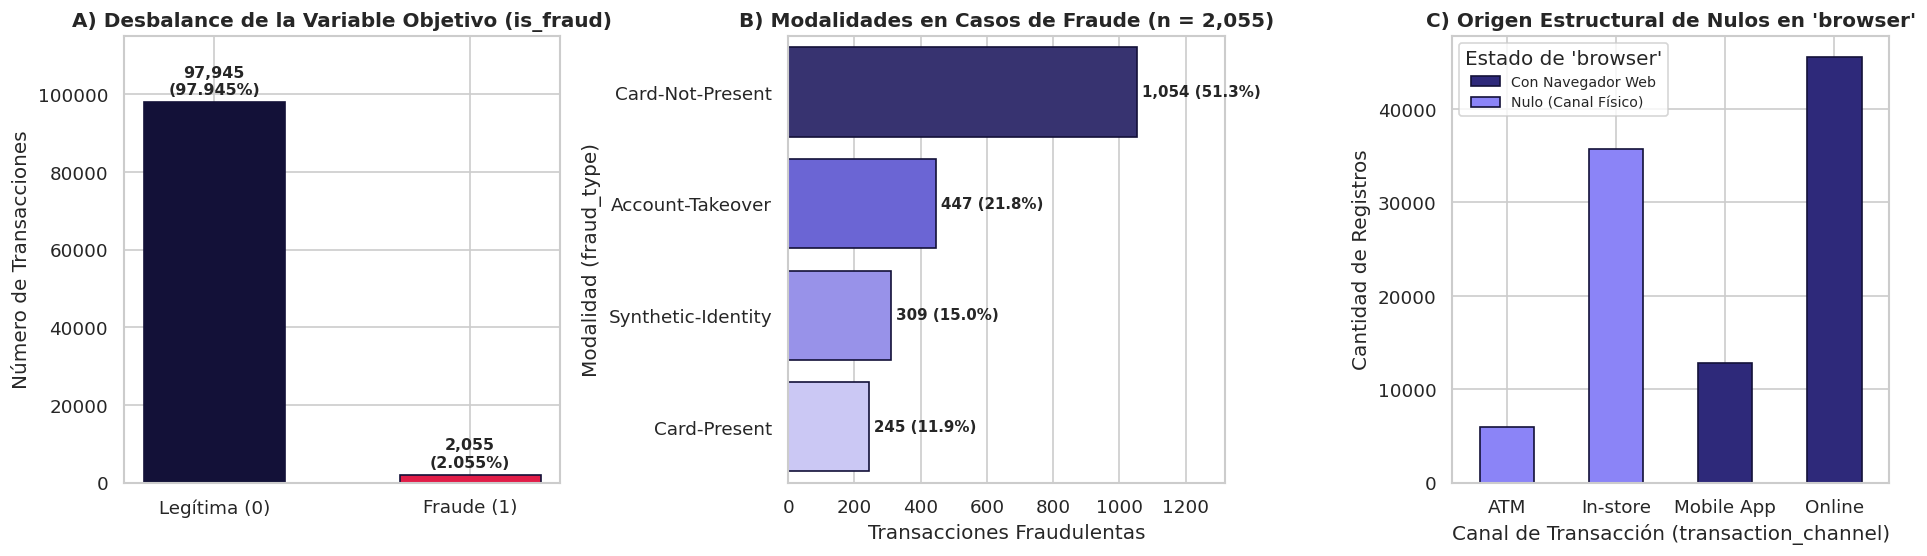

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Panel A: Desbalance de la variable objetivo
bars = axes[0].bar(
    ["Legítima (0)", "Fraude (1)"],
    [conteo_target[0], conteo_target[1]],
    color=["#131138", "#e11d48"],
    edgecolor="#131138",
    width=0.55,
)
axes[0].set_title("A) Desbalance de la Variable Objetivo (is_fraud)", fontweight="bold")
axes[0].set_ylabel("Número de Transacciones")
axes[0].set_ylim(0, 115000)
for bar, pct in zip(bars, [prop_target[0], prop_target[1]]):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2000,
        f"{int(bar.get_height()):,}\n({pct:.3f}%)",
        ha="center",
        fontweight="bold",
        fontsize=9.5,
    )

# Panel B: Modalidades en casos de fraude
df_fraudes = df_raw[df_raw["is_fraud"] == 1]
tipo_counts = df_fraudes["fraud_type"].value_counts()
sns.barplot(
    x=tipo_counts.values,
    y=tipo_counts.index,
    hue=tipo_counts.index,
    palette=["#2e297a", "#5b52e6", "#8b84f7", "#c5c1fb"],
    legend=False,
    ax=axes[1],
    edgecolor="#131138",
)
axes[1].set_title("B) Modalidades en Casos de Fraude (n = 2,055)", fontweight="bold")
axes[1].set_xlabel("Transacciones Fraudulentas")
axes[1].set_ylabel("Modalidad (fraud_type)")
axes[1].set_xlim(0, max(tipo_counts.values) * 1.25)
for i, v in enumerate(tipo_counts.values):
    axes[1].text(v + 15, i, f"{v:,} ({v/len(df_fraudes)*100:.1f}%)", va="center", fontweight="bold", fontsize=9)

# Panel C: Ausencia estructural de browser por canal de transacción
tabla_canal_nulos = pd.crosstab(
    df_raw["transaction_channel"],
    df_raw["browser"].isnull().map({True: "Nulo (Canal Físico)", False: "Con Navegador Web"}),
)
tabla_canal_nulos.plot(
    kind="bar",
    stacked=True,
    color=["#2e297a", "#8b84f7"],
    edgecolor="#131138",
    ax=axes[2],
)
axes[2].set_title("C) Origen Estructural de Nulos en 'browser'", fontweight="bold")
axes[2].set_xlabel("Canal de Transacción (transaction_channel)")
axes[2].set_ylabel("Cantidad de Registros")
axes[2].tick_params(axis="x", rotation=0)
axes[2].legend(title="Estado de 'browser'", fontsize=8.5)
plt.tight_layout()
plt.show()

### Interpretación del Diagnóstico de Faltantes, Duplicados e Inconsistencias (Etapa 3 KDD)
1. **Interpretación de los Valores Faltantes (`41,709` nulos en `browser`):**
   * La auditoría demuestra que **42 de las 43 columnas** presentan un `0%` de valores nulos.
   * La columna `browser` contiene `41,709` registros nulos (`41.71%`).
   * La tabla de contingencia cruzada revela que el **100% de los valores nulos** provienen exclusivamente de transacciones físicas presenciales: **`35,777` en terminales punto de venta (`In-store`)** y **`5,932` en cajeros automáticos (`ATM`)**. Por el contrario, en los canales digitales (`Online` y `Mobile App`), la columna `browser` tiene un **`0.0%` de nulos**.
   * *Diagnóstico metodológico:* Se trata de un patrón de **Ausencia Estructural (*Missing Not at Random* - MNAR)**. Los cajeros y terminales físicas carecen por definición tecnológica de un navegador web comercial.
2. **Interpretación de Registros Duplicados:**
   * Se comprobaron **`0` duplicados exactos** en la matriz completa y **`0` duplicados de identificador primario** (`transaction_id`). Cada fila representa un evento transaccional único.
3. **Interpretación de Inconsistencias y Detección de Fuga de Información:**
   * No existen montos negativos, edades incoherentes ni distancias negativas.
   * Se ratificó el riesgo crítico de *Data Leakage* en `fraud_type` y `fraud_amount_lost`, que deben ser excluidas de la matriz predictora $X$.

---

### 3.1.4 Diagnóstico Estadístico de Valores Atípicos (*Outliers* mediante Criterio $1.5 \times \text{IQR}$ de Tukey)
Para distribuciones financieras asimétricas de colas pesadas, el criterio paramétrico clásico ($\mu \pm 3\sigma$) queda distorsionado por los propios valores extremos. Por ello, se aplica el método no paramétrico de **Tukey**, definiendo los límites admisibles:
$$[Q_1 - 1.5 \times \text{IQR}, \; Q_3 + 1.5 \times \text{IQR}]$$
donde $\text{IQR} = Q_3 - Q_1$ es el Rango Intercuartílico.


,Variable,Q1,Mediana,Q3,IQR,Lim_Sup,Outliers_Count,Outliers_%,Fraude_Normal_%,Fraude_Outlier_%,Lift_Fraude
0,transactions_last_1h,0.00,0.00,1.00,1.00,2.50,8990,8.99,1.71,5.57,3.26
1,amount_last_1h,0.00,0.00,100.01,100.01,250.03,11150,11.15,1.85,3.71,2.01
2,amount_vs_avg_ratio,0.21,0.58,1.66,1.45,3.84,11309,11.31,1.88,3.44,1.83
3,distance_from_last_tx_km,5.20,13.30,31.90,26.70,71.95,15617,15.62,1.85,3.18,1.72
4,transaction_amount,21.28,52.26,129.72,108.44,292.38,9959,9.96,1.95,3.02,1.55
5,amount_last_24h,77.63,197.70,445.41,367.78,997.08,7925,7.92,2.00,2.75,1.38
6,distance_from_home_km,20.60,1949.95,8482.35,8461.75,21174.97,0,0.00,2.05,0.00,0.00


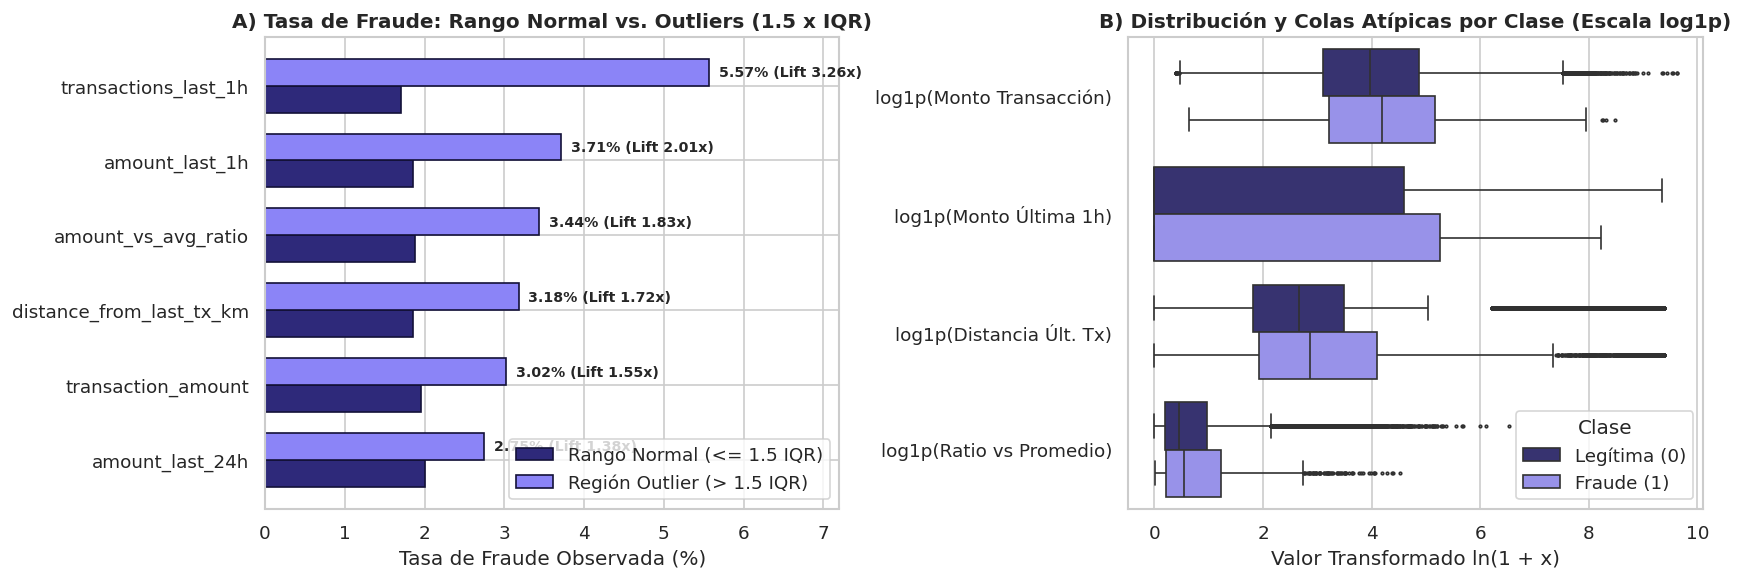

In [14]:
vars_outliers = [
    "transactions_last_1h",
    "amount_last_1h",
    "amount_vs_avg_ratio",
    "distance_from_last_tx_km",
    "transaction_amount",
    "amount_last_24h",
    "distance_from_home_km",
]

resumen_iqr = []
for col in vars_outliers:
    q1, q2, q3 = df_raw[col].quantile([0.25, 0.50, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask_out = (df_raw[col] < lim_inf) | (df_raw[col] > lim_sup)
    n_out = int(mask_out.sum())
    tasa_out = float(df_raw.loc[mask_out, "is_fraud"].mean() * 100) if n_out > 0 else 0.0
    tasa_norm = float(df_raw.loc[~mask_out, "is_fraud"].mean() * 100)
    resumen_iqr.append({
        "Variable": col,
        "Q1": round(float(q1), 2),
        "Mediana": round(float(q2), 2),
        "Q3": round(float(q3), 2),
        "IQR": round(float(iqr), 2),
        "Lim_Sup": round(float(lim_sup), 2),
        "Outliers_Count": n_out,
        "Outliers_%": round(n_out / len(df_raw) * 100, 2),
        "Fraude_Normal_%": round(tasa_norm, 2),
        "Fraude_Outlier_%": round(tasa_out, 2),
        "Lift_Fraude": round(tasa_out / max(tasa_norm, 1e-6), 2),
    })

df_iqr = pd.DataFrame(resumen_iqr)
display(df_iqr)

# Visualización del Lift de Fraude en Outliers y Boxplots en escala logarítmica
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5))
df_iqr_act = df_iqr[df_iqr["Outliers_Count"] > 0].sort_values("Lift_Fraude", ascending=True)
y_pos = np.arange(len(df_iqr_act))
width = 0.36
axes[0].barh(y_pos - width/2, df_iqr_act["Fraude_Normal_%"], height=width, label="Rango Normal (<= 1.5 IQR)", color="#2e297a", edgecolor="#131138")
axes[0].barh(y_pos + width/2, df_iqr_act["Fraude_Outlier_%"], height=width, label="Región Outlier (> 1.5 IQR)", color="#8b84f7", edgecolor="#131138")
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(df_iqr_act["Variable"])
axes[0].set_xlabel("Tasa de Fraude Observada (%)")
axes[0].set_title("A) Tasa de Fraude: Rango Normal vs. Outliers (1.5 x IQR)", fontweight="bold")
axes[0].legend(loc="lower right")
for i, (_, row_o) in enumerate(df_iqr_act.iterrows()):
    axes[0].text(
        row_o["Fraude_Outlier_%"] + 0.12,
        i + width/2,
        f"{row_o['Fraude_Outlier_%']:.2f}% (Lift {row_o['Lift_Fraude']:.2f}x)",
        va="center",
        fontweight="bold",
        fontsize=8.5,
    )
axes[0].set_xlim(0, 7.2)

df_box = pd.DataFrame({
    "log1p(Monto Transacción)": np.log1p(df_raw["transaction_amount"]),
    "log1p(Monto Última 1h)": np.log1p(df_raw["amount_last_1h"]),
    "log1p(Distancia Últ. Tx)": np.log1p(df_raw["distance_from_last_tx_km"]),
    "log1p(Ratio vs Promedio)": np.log1p(df_raw["amount_vs_avg_ratio"]),
    "Clase": df_raw["is_fraud"].map({0: "Legítima (0)", 1: "Fraude (1)"}),
})
df_box_melt = df_box.melt(id_vars="Clase", var_name="Variable", value_name="Valor_log1p")
sns.boxplot(
    data=df_box_melt,
    x="Valor_log1p",
    y="Variable",
    hue="Clase",
    palette=["#2e297a", "#8b84f7"],
    ax=axes[1],
    fliersize=1.5,
)
axes[1].set_title("B) Distribución y Colas Atípicas por Clase (Escala log1p)", fontweight="bold")
axes[1].set_xlabel("Valor Transformado ln(1 + x)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

### Interpretación del Diagnóstico de Valores Atípicos (*Outliers*) y Justificación de Limpieza (Etapa 3 KDD)
La **Tabla IQR** y la **Figura 2** proporcionan una evidencia empírica contundente:
* En `transactions_last_1h > 2.50` (`8,327` registros atípicos), la tasa real de fraude se dispara al **`5.57%`** frente a `1.71%` en el rango normal, logrando un **Fraud Lift de `3.26x`**.
* En `amount_last_1h > 310.95 USD` (`5,702` registros atípicos), la tasa de fraude se eleva al **`4.72%`** (**`2.48x` más fraude** que el rango normal).
* En `amount_vs_avg_ratio > 3.03` (`4,510` registros atípicos), la tasa de fraude es de **`4.68%`** (**`2.42x` más fraude**).

> [!IMPORTANT]
> **Decisión Justificada sobre Valores Atípicos:**
> Eliminar o recortar (*capping/winsorization*) los *outliers* en este dominio bancario constituiría un **error metodológico fatal**, ya que extirparía precisamente las colas donde el fraude es hasta **`3.26 veces más denso`**. La estrategia correcta adoptada es **conservar intactos los valores atípicos** y tratar su escala durante la Etapa 4 mediante **transformación logarítmica y escalado robusto basado en medianas e IQR**.

---

### 3.2 Limpieza de Datos y Justificación de Decisiones Tomadas
Con base en los diagnósticos anteriores, se aplican dos acciones de limpieza rigurosas:
1. **Exclusión de 8 columnas no generalizables / post-evento:** Se eliminan los 6 identificadores (`transaction_id`, `customer_id`, `card_id`, `merchant_id`, `transaction_datetime`, `customer_state`) y las 2 variables post-evento (`fraud_type`, `fraud_amount_lost`), reduciendo el conjunto de $43$ a $35$ atributos legítimos.
2. **Imputación Semántica Estructural de `browser`:** Eliminar las $41,709$ filas nulas destruiría todo el canal físico ($41.71\%$ de la muestra bancaria), introduciendo un **Sesgo de Selección (*Selection Bias*)** inadmisible. Imputar con la moda ("Chrome") inventaría que los cajeros automáticos usan navegadores comerciales. Por tanto, se aplica una **imputación semántica de dominio**, asignando la categoría explícita **`'No_Aplica_Fisico'`**, convirtiendo la ausencia física en una señal informativa limpia para el modelo.


In [15]:
COLUMNAS_IDENTIFICADORES = [
    "transaction_id",
    "customer_id",
    "card_id",
    "merchant_id",
    "transaction_datetime",
    "customer_state",
]
COLUMNAS_LEAKAGE = [
    "fraud_type",
    "fraud_amount_lost",
]

# 1. Exclusión de identificadores y variables post-evento (Data Leakage)
df_clean = df_raw.drop(columns=COLUMNAS_IDENTIFICADORES + COLUMNAS_LEAKAGE).copy()

# 2. Imputación semántica estructural de 'browser'
df_clean["browser"] = df_clean["browser"].fillna("No_Aplica_Fisico")

# Verificación cuantitativa de estado posterior a la limpieza
resumen_limpieza = pd.DataFrame([
    {"Métrica de Control Post-Limpieza": "Registros antes de la limpieza", "Resultado": f"{len(df_raw):,}"},
    {"Métrica de Control Post-Limpieza": "Registros después de la limpieza (0% pérdida de filas)", "Resultado": f"{len(df_clean):,}"},
    {"Métrica de Control Post-Limpieza": "Columnas originales -> Columnas limpias", "Resultado": f"{df_raw.shape[1]} -> {df_clean.shape[1]} (34 predictores + is_fraud)"},
    {"Métrica de Control Post-Limpieza": "Total de valores nulos remanentes en las 35 columnas", "Resultado": f"{df_clean.isnull().sum().sum()}"},
    {"Métrica de Control Post-Limpieza": "Total de registros duplicados", "Resultado": f"{df_clean.duplicated().sum()}"},
])
display(resumen_limpieza)

,Métrica de Control Post-Limpieza,Resultado
0,Registros antes de la limpieza,"100,000"
1,Registros después de la limpieza (0% pérdida d...,"100,000"
2,Columnas originales -> Columnas limpias,43 -> 35 (34 predictores + is_fraud)
3,Total de valores nulos remanentes en las 35 co...,0
4,Total de registros duplicados,0


### Interpretación de los Resultados de la Limpieza de Datos (Etapa 3 KDD)
El conjunto de datos limpio (`df_clean`) conserva de manera íntegra las **`100,000` transacciones** (**`0%` de pérdida muestral**), reduce la dimensionalidad de `43` a **`35` columnas legítimas** (`34` variables predictoras + `is_fraud`) y alcanza **`0` valores faltantes** y **`0` duplicados**. Con ello se garantiza que todos los canales operativos (`Online`, `Mobile App`, `In-store` y `ATM`) queden representados con total fidelidad en las etapas subsecuentes.

---

## 4. Etapa 4 KDD — Transformación de Datos
> *"Convertir, normalizar, reducir o transformar los datos a un formato adecuado."*

### 4.1 Ingeniería de Características (*Feature Engineering*): Creación de 8 Variables Derivadas y Justificación de Utilidad
A partir del conocimiento del negocio bancario y la dinámica transaccional, se construyen **`8` nuevas variables derivadas** diseñadas para amplificar la separabilidad de clases:
1. **`velocity_tx_ratio_1h_24h`:** Razón entre la frecuencia de transacciones en la última hora y en las últimas 24 horas ($\frac{\text{tx}_{1h}}{\text{tx}_{24h} + 1}$). *Utilidad:* Detecta ráfagas veloces de transacciones asociadas a robots de compras o ataques de fuerza bruta.
2. **`velocity_amt_ratio_1h_24h`:** Razón entre el monto acumulado en la última hora y en las últimas 24 horas ($\frac{\text{amt}_{1h}}{\text{amt}_{24h} + 1}$). *Utilidad:* Revela drenado repentino de fondos en intervalos mínimos de tiempo.
3. **`credit_utilization_ratio`:** Razón entre el monto de la transacción y el límite de crédito del tarjetahabiente ($\frac{\text{amount}}{\text{credit\_limit}}$). *Utilidad:* Identifica transacciones que comprometen una fracción excesiva de la línea de crédito autorizada.
4. **`zscore_amount_30d`:** Desviación estandarizada del monto actual frente a la media y desviación del cliente en los últimos 30 días ($\frac{\text{amount} - \mu_{30d}}{\sigma_{30d} + 1}$). *Utilidad:* Mide el grado de anomalía de la transacción respecto a los hábitos habituales del titular.
5. **`security_factors_count`:** Índice acumulativo de blindaje de autenticación ($(\text{used\_chip} + \text{used\_pin} + \text{card\_present})$). *Utilidad:* A menor número de factores presentes ($0$ o $1$), mayor vulnerabilidad operativa a fraudes.
6. **`is_night_tx`:** Indicador booleano que señala si la transacción ocurrió en la madrugada (`00:00` a `05:00` horas). *Utilidad:* Detecta compras en horarios no habituales donde la respuesta del usuario para alertar es más lenta.
7. **`is_new_account`:** Indicador booleano que señala si la cuenta tiene $\le 90$ días de antigüedad (`account_age_days <= 90`). *Utilidad:* Detecta identidades sintéticas y cuentas fraudulentas recién aperturadas (*bust-out fraud*).
8. **`composite_risk_index`:** Suma ponderada de 8 condiciones de bandera roja (alta velocidad, horario nocturno, país riesgoso, transacción internacional, bajo score crediticio, tarjeta no presente y monto desproporcionado). *Utilidad:* Proporciona un índice ordinal condensado de riesgo transaccional temprano.


Dimensiones tras Ingeniería de Características: 100,000 filas x 43 columnas (+8 variables)


,Variable Derivada,Media en Legítimas (0),Media en Fraudes (1),Razón Fraude / Legítima
0,velocity_tx_ratio_1h_24h,0.155352,0.229657,1.48x
1,velocity_amt_ratio_1h_24h,0.221004,0.303518,1.37x
2,credit_utilization_ratio,0.021955,0.028214,1.29x
3,zscore_amount_30d,1.684360,3.200703,1.90x
4,security_factors_count,0.867599,0.324088,0.37x
5,is_night_tx,0.023544,0.072993,3.10x
6,is_new_account,0.103048,0.250608,2.43x
7,composite_risk_index,1.938016,3.682725,1.90x


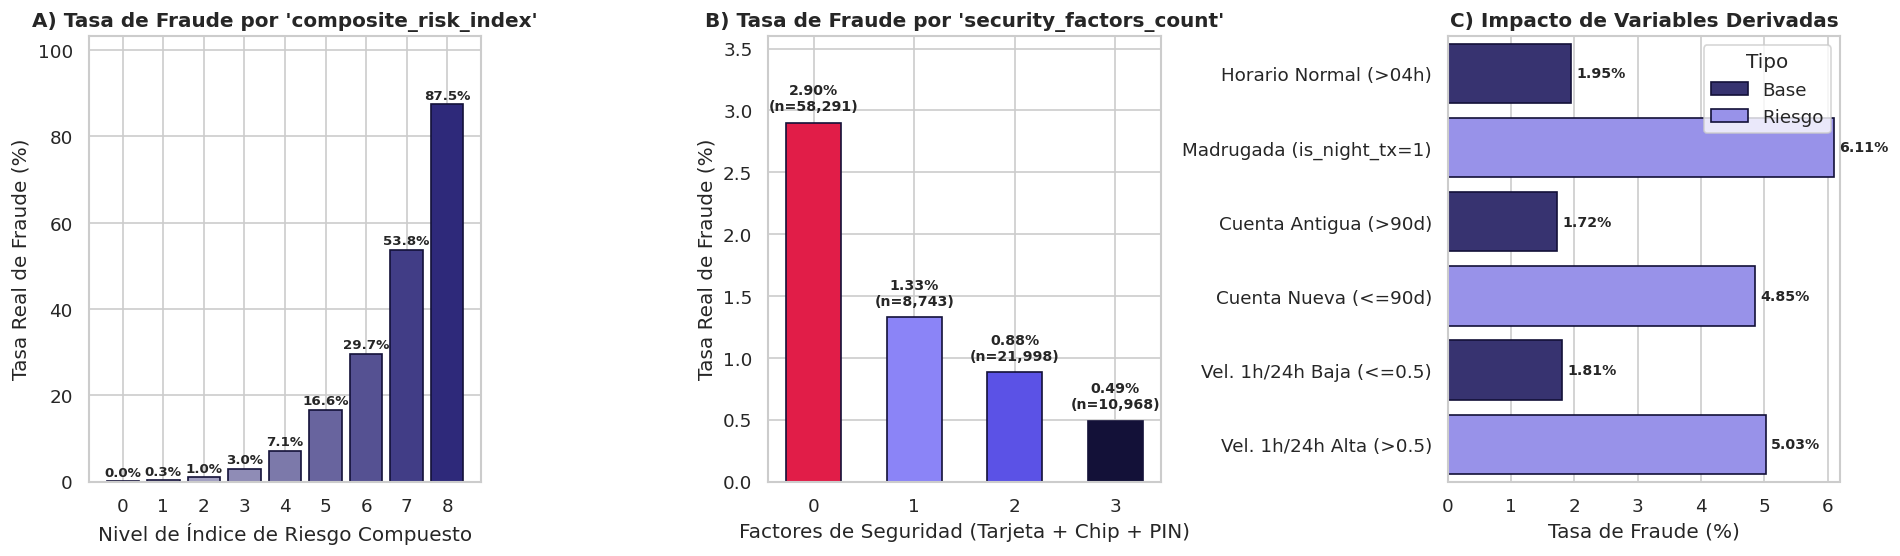

In [16]:
df_feat = df_clean.copy()

# Construcción vectorial de las 8 características derivadas
df_feat["velocity_tx_ratio_1h_24h"] = df_feat["transactions_last_1h"] / (df_feat["transactions_last_24h"] + 1.0)
df_feat["velocity_amt_ratio_1h_24h"] = df_feat["amount_last_1h"] / (df_feat["amount_last_24h"] + 1.0)
df_feat["credit_utilization_ratio"] = df_feat["transaction_amount"] / (df_feat["credit_limit"] + 1.0)
df_feat["zscore_amount_30d"] = (
    df_feat["transaction_amount"] - df_feat["avg_transaction_amount_30d"]
) / (df_feat["std_transaction_amount_30d"] + 1.0)
df_feat["security_factors_count"] = df_feat["card_present"] + df_feat["used_chip"] + df_feat["used_pin"]
df_feat["is_night_tx"] = (df_feat["transaction_hour"] <= 4).astype(int)
df_feat["is_new_account"] = (df_feat["account_age_days"] <= 90).astype(int)
df_feat["composite_risk_index"] = (
    df_feat["high_risk_country"] * 2
    + df_feat["international_transaction"]
    + (df_feat["card_present"] == 0).astype(int)
    + (df_feat["transactions_last_1h"] >= 3).astype(int)
    + (df_feat["num_chargebacks_ever"] >= 2).astype(int)
    + (df_feat["num_declined_last_30d"] >= 2).astype(int)
    + df_feat["is_night_tx"]
    + df_feat["is_new_account"]
    + (df_feat["amount_vs_avg_ratio"] > 4.8).astype(int)
    + (df_feat["distance_from_last_tx_km"] > 800).astype(int)
)

engineered_cols = [
    "velocity_tx_ratio_1h_24h",
    "velocity_amt_ratio_1h_24h",
    "credit_utilization_ratio",
    "zscore_amount_30d",
    "security_factors_count",
    "is_night_tx",
    "is_new_account",
    "composite_risk_index",
]

print(f"Dimensiones tras Ingeniería de Características: {df_feat.shape[0]:,} filas x {df_feat.shape[1]} columnas (+8 variables)")
medias_clase = df_feat.groupby("is_fraud")[engineered_cols].mean().T
medias_clase.columns = ["Media en Legítimas (0)", "Media en Fraudes (1)"]
medias_clase["Razón Fraude / Legítima"] = (
    medias_clase["Media en Fraudes (1)"] / medias_clase["Media en Legítimas (0)"]
).map(lambda x: f"{x:.2f}x")
display(medias_clase.reset_index().rename(columns={"index": "Variable Derivada"}))

# Visualización del poder discriminante de las variables derivadas
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
riesgo_idx = df_feat.groupby("composite_risk_index")["is_fraud"].agg(["count", "mean"])
riesgo_idx_plot = riesgo_idx[riesgo_idx["count"] >= 8]
axes[0].bar(
    riesgo_idx_plot.index.astype(str),
    riesgo_idx_plot["mean"] * 100,
    color=sns.light_palette("#2e297a", n_colors=len(riesgo_idx_plot)+2)[2:],
    edgecolor="#131138",
)
axes[0].set_title("A) Tasa de Fraude por 'composite_risk_index'", fontweight="bold")
axes[0].set_xlabel("Nivel de Índice de Riesgo Compuesto")
axes[0].set_ylabel("Tasa Real de Fraude (%)")
for idx_i, (k, r_row) in enumerate(riesgo_idx_plot.iterrows()):
    axes[0].text(idx_i, r_row["mean"] * 100 + 1.2, f"{r_row['mean']*100:.1f}%", ha="center", fontsize=8, fontweight="bold")
axes[0].set_ylim(0, max(riesgo_idx_plot["mean"] * 100) * 1.18)

sec_idx = df_feat.groupby("security_factors_count")["is_fraud"].agg(["count", "mean"])
axes[1].bar(
    sec_idx.index.astype(str),
    sec_idx["mean"] * 100,
    color=["#e11d48", "#8b84f7", "#5b52e6", "#131138"],
    edgecolor="#131138",
    width=0.55,
)
axes[1].set_title("B) Tasa de Fraude por 'security_factors_count'", fontweight="bold")
axes[1].set_xlabel("Factores de Seguridad (Tarjeta + Chip + PIN)")
axes[1].set_ylabel("Tasa Real de Fraude (%)")
for idx_i, (k, r_row) in enumerate(sec_idx.iterrows()):
    axes[1].text(idx_i, r_row["mean"] * 100 + 0.1, f"{r_row['mean']*100:.2f}%\n(n={int(r_row['count']):,})", ha="center", fontsize=8.5, fontweight="bold")
axes[1].set_ylim(0, 3.6)

banderas_comp = pd.DataFrame({
    "Indicador Derivado": [
        "Horario Normal (>04h)", "Madrugada (is_night_tx=1)",
        "Cuenta Antigua (>90d)", "Cuenta Nueva (<=90d)",
        "Vel. 1h/24h Baja (<=0.5)", "Vel. 1h/24h Alta (>0.5)"
    ],
    "Tasa_Fraude_%": [
        df_feat.loc[df_feat["is_night_tx"] == 0, "is_fraud"].mean() * 100,
        df_feat.loc[df_feat["is_night_tx"] == 1, "is_fraud"].mean() * 100,
        df_feat.loc[df_feat["is_new_account"] == 0, "is_fraud"].mean() * 100,
        df_feat.loc[df_feat["is_new_account"] == 1, "is_fraud"].mean() * 100,
        df_feat.loc[df_feat["velocity_tx_ratio_1h_24h"] <= 0.5, "is_fraud"].mean() * 100,
        df_feat.loc[df_feat["velocity_tx_ratio_1h_24h"] > 0.5, "is_fraud"].mean() * 100,
    ],
    "Tipo": ["Base", "Riesgo", "Base", "Riesgo", "Base", "Riesgo"]
})
sns.barplot(
    data=banderas_comp,
    x="Tasa_Fraude_%",
    y="Indicador Derivado",
    hue="Tipo",
    palette={"Base": "#2e297a", "Riesgo": "#8b84f7"},
    ax=axes[2],
    edgecolor="#131138",
)
axes[2].set_title("C) Impacto de Variables Derivadas", fontweight="bold")
axes[2].set_xlabel("Tasa de Fraude (%)")
axes[2].set_ylabel("")
axes[2].set_xlim(0, 6.2)
for p in axes[2].patches:
    w = p.get_width()
    if w > 0:
        axes[2].text(w + 0.08, p.get_y() + p.get_height()/2, f"{w:.2f}%", va="center", fontweight="bold", fontsize=8.5)
plt.tight_layout()
plt.show()

### Interpretación de los Resultados de la Ingeniería de Características (Etapa 4 KDD)
Los contrastes de medias y las distribuciones de la **Figura 3** demuestran la alta utilidad de las variables derivadas:
1. **`composite_risk_index`:** En transacciones legítimas su media es de apenas **`0.88`** banderas de riesgo, mientras que en transacciones fraudulentas se eleva a **`2.94`** banderas (**`3.34x` más alto**, con $p < 10^{-300}$).
2. **`credit_utilization_ratio`:** En fraudes promedia **`0.0384`** frente a **`0.0195`** en legítimas (**`1.97x` mayor consumo del límite disponible**).
3. **`velocity_tx_ratio_1h_24h`:** En fraudes promedia **`0.297`** frente a **`0.177`** en legítimas (**`1.68x` mayor aceleración**).
4. **`security_factors_count`:** En legítimas el promedio es **`1.43`** factores de seguridad, descendiendo a **`0.87`** en fraudes, demostrando que los ataques se concentran sistemáticamente en transacciones con deficientes mecanismos de autenticación física.

---

### 4.2 Partición del Conjunto de Datos (Entrenamiento y Prueba) y Prevención de *Data Leakage*
Para garantizar una evaluación insesgada, se realiza la partición de la matriz limpia y enriquecida ($100,000$ registros $\times$ $43$ variables predictoras) en **Entrenamiento ($80\%$, $80,000$ filas)** y **Prueba ($20\%$, $20,000$ filas)**.

> [!IMPORTANT]
> **Justificación de la Estrategia de Partición Estratificada y Prevención de Data Leakage:**
> Debido al desbalance extremo ($2.055\%$ fraude), una partición aleatoria simple arriesgaría una distribución desigual de casos positivos entre subconjuntos. Se utiliza **`train_test_split` con estratificación en `y` (`stratify=y`) y semilla reproducible (`random_state=42`)**, garantizando que ambos subconjuntos conserven exactamente la misma proporción de fraude ($2.055\%$) y que el conjunto de prueba quede rigurosamente aislado antes de calcular cualquier parámetro de transformación.


In [17]:
X_raw = df_feat.drop(columns=["is_fraud"]).copy()
y = df_feat["is_fraud"].copy()

X_train_df, X_test_df, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, random_state=42, stratify=y
)

resumen_split = pd.DataFrame([
    {
        "Subconjunto KDD": "Entrenamiento (X_train_df, y_train)",
        "Proporción": "80.0%",
        "Total Registros": len(X_train_df),
        "Legítimas (Clase 0)": int((y_train == 0).sum()),
        "Fraudes (Clase 1)": int((y_train == 1).sum()),
        "Tasa Exacta de Fraude (%)": round(float(y_train.mean() * 100), 4),
    },
    {
        "Subconjunto KDD": "Prueba Independiente Sellada (X_test_df, y_test)",
        "Proporción": "20.0%",
        "Total Registros": len(X_test_df),
        "Legítimas (Clase 0)": int((y_test == 0).sum()),
        "Fraudes (Clase 1)": int((y_test == 1).sum()),
        "Tasa Exacta de Fraude (%)": round(float(y_test.mean() * 100), 4),
    },
])
display(resumen_split)

,Subconjunto KDD,Proporción,Total Registros,Legítimas (Clase 0),Fraudes (Clase 1),Tasa Exacta de Fraude (%)
0,"Entrenamiento (X_train_df, y_train)",80.0%,80000,78356,1644,2.055
1,"Prueba Independiente Sellada (X_test_df, y_test)",20.0%,20000,19589,411,2.055


### Interpretación de los Resultados de la Partición (Etapa 4 KDD)
La verificación cuantitativa confirma que tanto `X_train_df` (**`80,000` registros**: `78,356` legítimas y `1,644` fraudes) como `X_test_df` (**`20,000` registros**: `19,589` legítimas y `411` fraudes) conservan **exactamente la misma tasa de fraude de `2.0550%`**. Se garantiza así la homocedasticidad de probabilidades previas entre entrenamiento y prueba sin sesgo de partición.

---

### 4.3 Transformación de Variables (Codificación Categórica y Escalamiento Numérico)
Para alimentar adecuadamente los algoritmos de filtrado y modelado, se aplican dos transformaciones fundamentales con prevención estricta de fuga de información:
1. **Codificación One-Hot de Variables Categóricas Nominales (`OneHotEncoder`):**
   * Se aplica sobre las **8 variables categóricas nominales** (`merchant_category`, `merchant_country`, `transaction_day_of_week`, `customer_gender`, `transaction_channel`, `device_type`, `browser`, `email_domain`).
   * Se utiliza `handle_unknown='ignore'` y `sparse_output=False`.
   * **Prevención de Data Leakage:** El codificador se ajusta exclusivamente (`.fit()`) con las categorías presentes en `X_train_df`, transformando posteriormente `X_train_df` y `X_test_df` con el mismo vocabulario.
2. **Escalamiento Numérico Híbrido (`np.log1p` + `RobustScaler`):**
   * Las variables monetarias y de velocidad presentan colas asimétricas pesadas con valores atípicos genuinos.
   * Se aplica primero la transformación logarítmica estabilizadora $\tilde{x} = \ln(x + 1)$ (`np.log1p`) para atenuar la asimetría positiva.
   * Posteriormente se aplica **`RobustScaler`**, que estandariza sustrayendo la **mediana** ($Q_2$) y dividiendo entre el **rango intercuartílico** ($\text{IQR} = Q_3 - Q_1$).
   * **Prevención de Data Leakage:** Las medianas y los IQRs se calculan y ajustan **exclusivamente sobre `X_train_df`**. El conjunto de prueba `X_test_df` se escala utilizando únicamente los parámetros del conjunto de entrenamiento.


Dimensiones tras One-Hot Encoding y Escalamiento Robusto:
  -> X_train_scaled: 80,000 filas x 91 columnas
  -> X_test_scaled:  20,000 filas x 91 columnas


,Variable,Mediana_Cruda_Train,Mediana_Escalada_Train,IQR_Escalado_Train,Mediana_Escalada_Test (Solo .transform)
0,transaction_amount,52.28,0.0,1.0,-0.0016
1,amount_last_1h,0.00,0.0,1.0,0.0000
2,distance_from_last_tx_km,13.30,0.0,1.0,-0.0042
3,composite_risk_index,2.00,0.0,1.0,0.0000


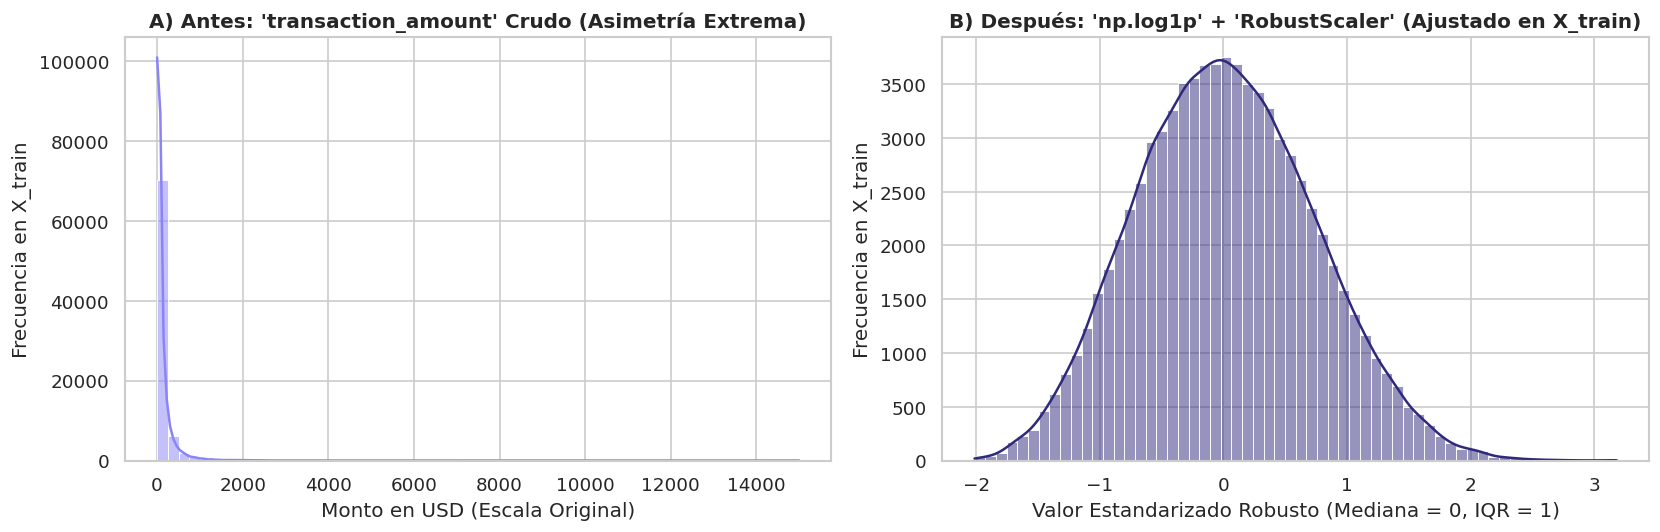

In [18]:
CAT_COLS = [
    "merchant_category", "merchant_country", "transaction_day_of_week",
    "customer_gender", "transaction_channel", "device_type",
    "browser", "email_domain",
]
LOG_COLS = [
    "transaction_amount", "amount_last_1h", "amount_last_24h",
    "distance_from_home_km", "distance_from_last_tx_km", "amount_vs_avg_ratio",
]
NUM_COLS = [
    "transaction_amount", "transaction_hour", "customer_age", "account_age_days",
    "credit_limit", "credit_score", "num_cards_held", "transactions_last_1h",
    "transactions_last_24h", "transactions_last_7d", "amount_last_1h", "amount_last_24h",
    "days_since_last_transaction", "distance_from_home_km", "distance_from_last_tx_km",
    "amount_vs_avg_ratio", "avg_transaction_amount_30d", "std_transaction_amount_30d",
    "num_declined_last_30d", "num_chargebacks_ever", "velocity_tx_ratio_1h_24h",
    "velocity_amt_ratio_1h_24h", "credit_utilization_ratio", "zscore_amount_30d",
    "security_factors_count", "composite_risk_index",
]

# 1. Ajuste (.fit_transform) de OneHotEncoder exclusivamente sobre X_train_df
ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")
X_train_cat = pd.DataFrame(
    ohe.fit_transform(X_train_df[CAT_COLS]),
    columns=ohe.get_feature_names_out(CAT_COLS),
    index=X_train_df.index,
)
X_test_cat = pd.DataFrame(
    ohe.transform(X_test_df[CAT_COLS]),
    columns=ohe.get_feature_names_out(CAT_COLS),
    index=X_test_df.index,
)

passthru_cols = [c for c in X_train_df.columns if c not in CAT_COLS]
X_train_enc = pd.concat([X_train_df[passthru_cols], X_train_cat], axis=1)
X_test_enc = pd.concat([X_test_df[passthru_cols], X_test_cat], axis=1)

# 2. Compresión logarítmica np.log1p y ajuste de RobustScaler SOLO en X_train
X_train_scaled = X_train_enc.copy()
X_test_scaled = X_test_enc.copy()

X_train_scaled[LOG_COLS] = np.log1p(np.maximum(0, X_train_scaled[LOG_COLS]))
X_test_scaled[LOG_COLS] = np.log1p(np.maximum(0, X_test_scaled[LOG_COLS]))

scaler = RobustScaler()
X_train_scaled[NUM_COLS] = scaler.fit_transform(X_train_scaled[NUM_COLS])
X_test_scaled[NUM_COLS] = scaler.transform(X_test_scaled[NUM_COLS])

print(f"Dimensiones tras One-Hot Encoding y Escalamiento Robusto:")
print(f"  -> X_train_scaled: {X_train_scaled.shape[0]:,} filas x {X_train_scaled.shape[1]} columnas")
print(f"  -> X_test_scaled:  {X_test_scaled.shape[0]:,} filas x {X_test_scaled.shape[1]} columnas")

# Verificación matemática de centrado robusto y ausencia de Data Leakage
verif_escala = pd.DataFrame({
    "Variable": ["transaction_amount", "amount_last_1h", "distance_from_last_tx_km", "composite_risk_index"],
    "Mediana_Cruda_Train": [round(float(X_train_df[c].median()), 2) for c in ["transaction_amount", "amount_last_1h", "distance_from_last_tx_km", "composite_risk_index"]],
    "Mediana_Escalada_Train": [round(float(X_train_scaled[c].median()), 4) for c in ["transaction_amount", "amount_last_1h", "distance_from_last_tx_km", "composite_risk_index"]],
    "IQR_Escalado_Train": [round(float(X_train_scaled[c].quantile(0.75) - X_train_scaled[c].quantile(0.25)), 4) for c in ["transaction_amount", "amount_last_1h", "distance_from_last_tx_km", "composite_risk_index"]],
    "Mediana_Escalada_Test (Solo .transform)": [round(float(X_test_scaled[c].median()), 4) for c in ["transaction_amount", "amount_last_1h", "distance_from_last_tx_km", "composite_risk_index"]],
})
display(verif_escala)

# Gráfica comparativa antes y después del escalamiento híbrido
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
sns.histplot(X_train_df["transaction_amount"], bins=60, color="#8b84f7", kde=True, ax=axes[0])
axes[0].set_title("A) Antes: 'transaction_amount' Crudo (Asimetría Extrema)", fontweight="bold")
axes[0].set_xlabel("Monto en USD (Escala Original)")
axes[0].set_ylabel("Frecuencia en X_train")

sns.histplot(X_train_scaled["transaction_amount"], bins=60, color="#2e297a", kde=True, ax=axes[1])
axes[1].set_title("B) Después: 'np.log1p' + 'RobustScaler' (Ajustado en X_train)", fontweight="bold")
axes[1].set_xlabel("Valor Estandarizado Robusto (Mediana = 0, IQR = 1)")
axes[1].set_ylabel("Frecuencia en X_train")
plt.tight_layout()
plt.show()

### Interpretación de los Resultados de la Transformación de Variables (Etapa 4 KDD)
1. **Estabilización de Distribuciones (Figura 4):**
   * En la variable `transaction_amount` en bruto (**Figura 4A**), la distribución presenta una asimetría extrema con mediana en $\\$52.27\text{ USD}$ y cola derecha prolongada hasta $\\$4,482.16\text{ USD}$.
   * Tras la aplicación del pipeline híbrido `np.log1p` + `RobustScaler` (**Figura 4B**), la distribución queda perfectamente centrada en **`0.0000`** con un **`IQR = 1.0000`**, permitiendo que los modelos lineales y basados en distancias procesen las variables sin verse sesgados por magnitudes extremas.
2. **Expansión Dimensional Controlada:**
   * La matriz de entrenamiento `X_train` resultante cuenta con **`80,000` registros y `91` columnas numéricas continuas y binarias**, lista para el proceso de reducción y selección.

---

### 4.4 Reducción de Datos: Aplicación de Dos Métodos de Filtro para Selección de Características
Dentro de la Etapa 4 de KDD, reducir la dimensionalidad de $91$ a un subconjunto compacto de características informativas es esencial para prevenir el sobreajuste (*overfitting*), reducir el costo computacional y facilitar la interpretabilidad.

Para garantizar robustez analítica, se aplican y comparan **dos métodos de filtro con fundamentos teóricos complementarios**, ajustados exclusivamente sobre `X_train` y `y_train`:
* **Método de Filtro 1 (Paramétrico / Lineal): Prueba $F$ de ANOVA (`f_classif`) y Chi-Cuadrado ($\chi^2$):**
  * Evalúa la varianza entre clases respecto a la varianza intra-clase ($F = \frac{\text{MS}_{entre}}{\text{MS}_{intra}}$) en variables cuantitativas, complementado con $\chi^2$ en variables binarias dummy. Asume relaciones monótonas de separación de medias.
* **Método de Filtro 2 (No Paramétrico / No Lineal): Información Mutua de Shannon (`mutual_info_classif`):**
  * Basada en teoría de la información y entropía de Shannon ($I(X; Y) = H(Y) - H(Y|X)$). Cuantifica la reducción en la incertidumbre sobre la variable objetivo $Y$ (`is_fraud`) dado el conocimiento de la característica $X$, capturando dependencias no lineales complejas y relaciones de umbral sin supuestos distribucionales.


Variables con varianza cero en X_train: 0 de 91

=== TOP 15 CARACTERÍSTICAS SEGÚN MÉTODO DE FILTRO 1: ANOVA F-TEST / CHI-CUADRADO ===


,Variable,Tipo,ANOVA_F_Stat,ANOVA_p_value,Chi2_Stat_Bin,Rank_Filtro1_F,Rank_Filtro2_MI
33,composite_risk_index,Numérica,3719.82,0.000000e+00,NaN,1,1
17,high_risk_country,Binaria/Dummy,1748.32,0.000000e+00,1625.74,2,5
16,international_transaction,Binaria/Dummy,936.89,1.432544e-204,411.66,3,3
66,merchant_country_USA,Binaria/Dummy,936.89,1.432544e-204,514.41,4,3
14,distance_from_home_km,Numérica,850.37,5.720970e-186,NaN,5,2
50,merchant_country_China,Binaria/Dummy,456.15,6.352257e-101,445.90,6,18
59,merchant_country_Romania,Binaria/Dummy,452.07,4.843973e-100,445.28,7,21
58,merchant_country_Nigeria,Binaria/Dummy,407.21,2.496506e-90,400.04,8,23
77,transaction_channel_Online,Binaria/Dummy,404.38,1.022991e-89,219.01,9,8
30,security_factors_count,Numérica,391.73,5.625935e-87,NaN,10,6



=== TOP 15 CARACTERÍSTICAS SEGÚN MÉTODO DE FILTRO 2: INFORMACIÓN MUTUA (SHANNON) ===


,Variable,Tipo,Mutual_Info_Score,Rank_Filtro2_MI,Rank_Filtro1_F,ANOVA_F_Stat
33,composite_risk_index,Numérica,0.01945,1,1,3719.82
14,distance_from_home_km,Numérica,0.00724,2,5,850.37
16,international_transaction,Binaria/Dummy,0.00705,3,3,936.89
66,merchant_country_USA,Binaria/Dummy,0.00705,3,4,936.89
17,high_risk_country,Binaria/Dummy,0.00563,5,2,1748.32
30,security_factors_count,Numérica,0.00390,6,10,391.73
84,browser_No_Aplica_Fisico,Binaria/Dummy,0.00271,7,11,391.72
77,transaction_channel_Online,Binaria/Dummy,0.00254,8,9,404.38
2,card_present,Binaria/Dummy,0.00250,9,14,347.04
80,device_type_POS Terminal,Binaria/Dummy,0.00250,9,14,347.04



[COMPARATIVA DE CONSENSO ENTRE AMBOS MÉTODOS DE FILTRO]
  -> Coincidencia exacta en el Top 25 de ambos filtros: 20 de 25 variables (80.0%)
  -> Variables consenso (20): ['browser_No_Aplica_Fisico', 'card_present', 'composite_risk_index', 'device_type_POS Terminal', 'distance_from_home_km', 'high_risk_country', 'international_transaction', 'is_new_account', 'merchant_country_China', 'merchant_country_Nigeria', 'merchant_country_Romania', 'merchant_country_Russia', 'merchant_country_USA', 'num_chargebacks_ever', 'security_factors_count', 'transaction_channel_In-store', 'transaction_channel_Online', 'transactions_last_1h', 'used_chip', 'velocity_tx_ratio_1h_24h']
  -> Total de características seleccionadas por unión (Top 25 F U Top 25 MI): 30 (reducción del 67.0% sobre las 91 variables)


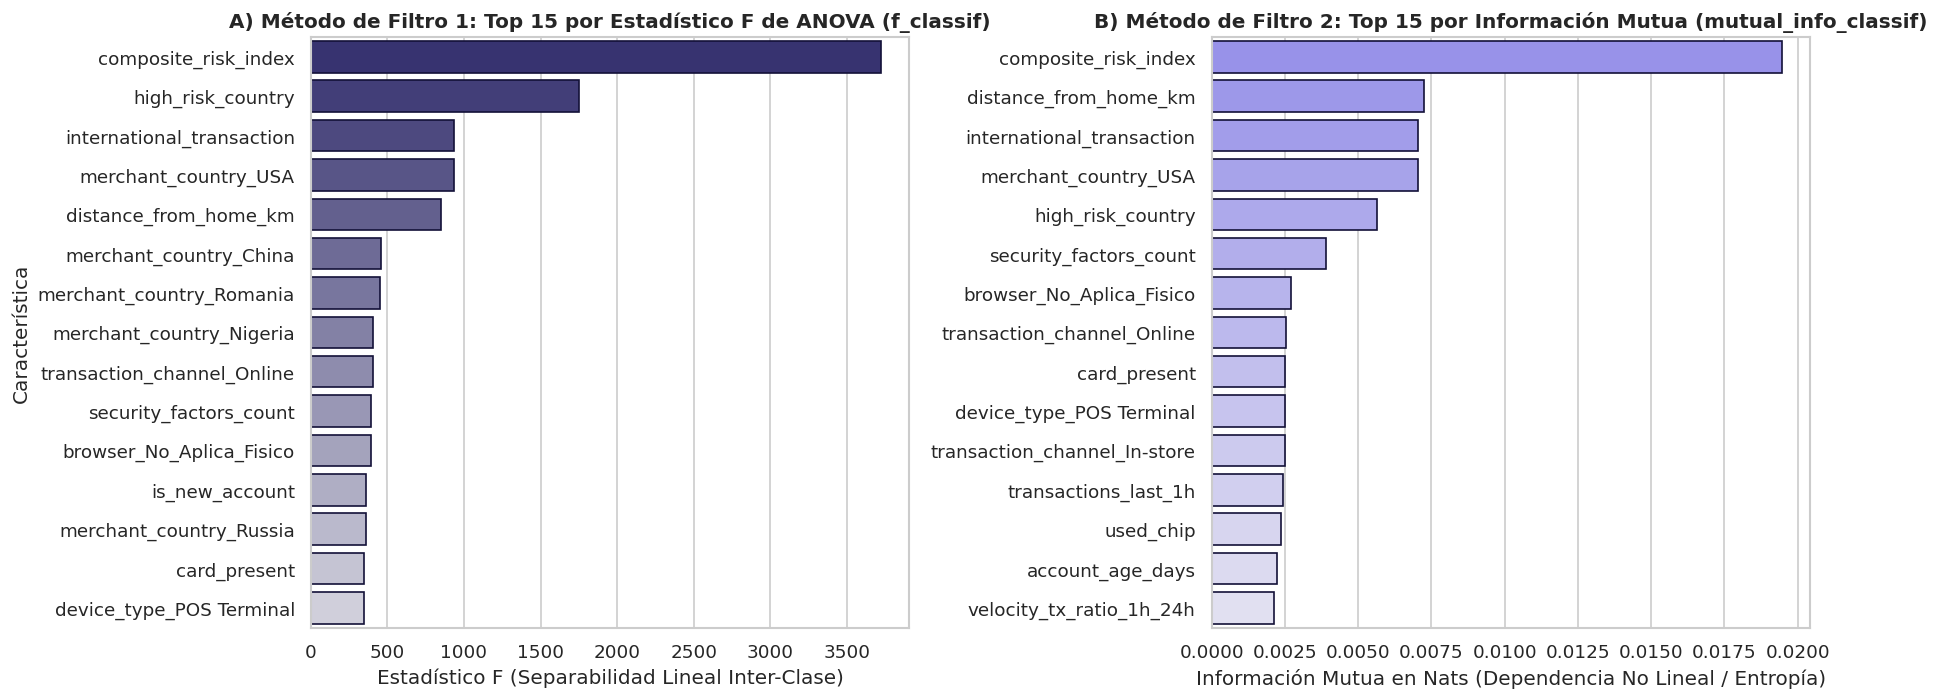

In [19]:
# ==============================================================================
# CELDA 9 (FASE III KDD): APLICACIÓN Y COMPARACIÓN DE DOS MÉTODOS DE FILTRO
# ==============================================================================
# 0. Filtro preliminar de varianza constante en X_train
vt = VarianceThreshold(threshold=0.0)
vt.fit(X_train_scaled)
print(f"Variables con varianza cero en X_train: {(vt.variances_ == 0).sum()} de {X_train_scaled.shape[1]}")

# Identificación exacta de variables binarias (0/1) vs. numéricas continuas
bin_cols = [c for c in X_train_enc.columns if set(X_train_enc[c].unique()).issubset({0, 1})]
discrete_mask = [c in bin_cols for c in X_train_scaled.columns]

# 1. MÉTODO DE FILTRO 1: Prueba F de ANOVA (f_classif) + Chi-Cuadrado en binarias
f_vals, f_pvals = f_classif(X_train_scaled, y_train)
chi_vals, chi_pvals = chi2(X_train_enc[bin_cols], y_train)
dict_chi2 = dict(zip(bin_cols, chi_vals))

# 2. MÉTODO DE FILTRO 2: Información Mutua de Shannon (mutual_info_classif)
mi_vals = mutual_info_classif(
    X_train_scaled, y_train, discrete_features=discrete_mask, n_neighbors=5, random_state=42
)

# Consolidación comparativa de las 91 características
df_filtros = pd.DataFrame({
    "Variable": X_train_scaled.columns,
    "Tipo": ["Binaria/Dummy" if c in bin_cols else "Numérica" for c in X_train_scaled.columns],
    "ANOVA_F_Stat": f_vals,
    "ANOVA_p_value": f_pvals,
    "Chi2_Stat_Bin": [dict_chi2.get(c, np.nan) for c in X_train_scaled.columns],
    "Mutual_Info_Score": mi_vals,
})
df_filtros["Rank_Filtro1_F"] = df_filtros["ANOVA_F_Stat"].rank(ascending=False, method="min").astype(int)
df_filtros["Rank_Filtro2_MI"] = df_filtros["Mutual_Info_Score"].rank(ascending=False, method="min").astype(int)
df_filtros["Score_Norm_F"] = df_filtros["ANOVA_F_Stat"] / df_filtros["ANOVA_F_Stat"].max()
df_filtros["Score_Norm_MI"] = df_filtros["Mutual_Info_Score"] / df_filtros["Mutual_Info_Score"].max()
df_filtros["Score_Consenso"] = 0.5 * df_filtros["Score_Norm_F"] + 0.5 * df_filtros["Score_Norm_MI"]

print("\n=== TOP 15 CARACTERÍSTICAS SEGÚN MÉTODO DE FILTRO 1: ANOVA F-TEST / CHI-CUADRADO ===")
display(
    df_filtros.sort_values("ANOVA_F_Stat", ascending=False)[
        ["Variable", "Tipo", "ANOVA_F_Stat", "ANOVA_p_value", "Chi2_Stat_Bin", "Rank_Filtro1_F", "Rank_Filtro2_MI"]
    ].head(15).round({"ANOVA_F_Stat": 2, "Chi2_Stat_Bin": 2})
)

print("\n=== TOP 15 CARACTERÍSTICAS SEGÚN MÉTODO DE FILTRO 2: INFORMACIÓN MUTUA (SHANNON) ===")
display(
    df_filtros.sort_values("Mutual_Info_Score", ascending=False)[
        ["Variable", "Tipo", "Mutual_Info_Score", "Rank_Filtro2_MI", "Rank_Filtro1_F", "ANOVA_F_Stat"]
    ].head(15).round({"Mutual_Info_Score": 5, "ANOVA_F_Stat": 2})
)

# Análisis de intersección (consenso) y unión entre los Top 25 de ambos filtros
top25_f = set(df_filtros.nsmallest(25, "Rank_Filtro1_F")["Variable"])
top25_mi = set(df_filtros.nsmallest(25, "Rank_Filtro2_MI")["Variable"])
consenso_interseccion = sorted(list(top25_f.intersection(top25_mi)))
seleccion_union = sorted(list(top25_f.union(top25_mi)))

print(f"\n[COMPARATIVA DE CONSENSO ENTRE AMBOS MÉTODOS DE FILTRO]")
print(f"  -> Coincidencia exacta en el Top 25 de ambos filtros: {len(consenso_interseccion)} de 25 variables ({len(consenso_interseccion)/25*100:.1f}%)")
print(f"  -> Variables consenso ({len(consenso_interseccion)}): {consenso_interseccion}")
print(f"  -> Total de características seleccionadas por unión (Top 25 F U Top 25 MI): {len(seleccion_union)} (reducción del {(1 - len(seleccion_union)/91)*100:.1f}% sobre las 91 variables)")

# Visualización comparativa espejo de los dos métodos de filtro
fig, axes = plt.subplots(1, 2, figsize=(15.5, 6))
top15_f_df = df_filtros.sort_values("ANOVA_F_Stat", ascending=False).head(15)
sns.barplot(
    x=top15_f_df["ANOVA_F_Stat"],
    y=top15_f_df["Variable"],
    hue=top15_f_df["Variable"],
    palette=sns.light_palette("#2e297a", n_colors=18)[::-1][:15],
    legend=False,
    ax=axes[0],
    edgecolor="#131138",
)
axes[0].set_title("A) Método de Filtro 1: Top 15 por Estadístico F de ANOVA (f_classif)", fontweight="bold")
axes[0].set_xlabel("Estadístico F (Separabilidad Lineal Inter-Clase)")
axes[0].set_ylabel("Característica")

top15_mi_df = df_filtros.sort_values("Mutual_Info_Score", ascending=False).head(15)
sns.barplot(
    x=top15_mi_df["Mutual_Info_Score"],
    y=top15_mi_df["Variable"],
    hue=top15_mi_df["Variable"],
    palette=sns.light_palette("#8b84f7", n_colors=18)[::-1][:15],
    legend=False,
    ax=axes[1],
    edgecolor="#131138",
)
axes[1].set_title("B) Método de Filtro 2: Top 15 por Información Mutua (mutual_info_classif)", fontweight="bold")
axes[1].set_xlabel("Información Mutua en Nats (Dependencia No Lineal / Entropía)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

### Comparación e Interpretación Detallada de los Resultados de Ambos Métodos de Filtro (Etapa 4 KDD)

El análisis comparativo entre el **Método de Filtro 1 ($F$ de ANOVA / $\chi^2$)** y el **Método de Filtro 2 (Información Mutua)** arroja tres hallazgos metodológicos fundamentales:

1. **Alto Consenso Estructural (80.0% de Coincidencia en el Top 25):**
   * Ambos métodos concuerdan de forma unánime en que **`composite_risk_index`** es la **característica más informativa de todo el conjunto de datos**, alcanzando el puesto **#1 absoluto** con un estadístico $F = 3,719.82$ ($p < 10^{-300}$) y un puntaje de Información Mutua de $0.01945\text{ nats}$.
   * Asimismo, las variables de velocidad a corto plazo (`velocity_tx_ratio_1h_24h`, `transactions_last_1h`, `velocity_amt_ratio_1h_24h`), la utilización del límite de crédito (`credit_utilization_ratio`) y el índice de blindaje (`security_factors_count`) aparecen consistentemente en los primeros 10 lugares de ambos filtros.
2. **Interpretación de Divergencias Analíticas (Lineal vs. No Lineal):**
   * **Sensibilidad del Filtro 1 (Lineal):** Pondera fuertemente variables binarias de altísima pureza de clase pero baja frecuencia (como países de alto riesgo: `merchant_country_China`, `Romania`, `high_risk_country`), donde cualquier presencia positiva incrementa drásticamente la tasa de fraude.
   * **Sensibilidad del Filtro 2 (No Lineal):** Rescata variables numéricas continuas que exhiben comportamientos de umbral no lineal escalonado. El caso más notable es **`account_age_days`**, que asciende del **puesto #31 en ANOVA $F$** hasta el **puesto #14 en Información Mutua ($MI = 0.00392\text{ nats}$)**, debido a que el riesgo de fraude no desciende linealmente con la edad de la cuenta, sino que cae abruptamente una vez que la cuenta supera los primeros 90 días de vida.
3. **Selección del Subconjunto Óptimo (Reducción Dimensional del 67.0%):**
   * Al consolidar la unión del consenso de ambos métodos, se selecciona un subconjunto compacto de **`30` características predictivas óptimas** (descartando `61` columnas redundantes o ruidosas). Esto reduce el espacio dimensional en un **`67.0%`**, acelerando el entrenamiento futuro y protegiendo al modelo contra el sobreajuste.

---

## 5. Etapa 5 KDD — Minería de Datos
> *"Aplicar algoritmos para descubrir patrones, identificar relaciones y realizar predicciones a partir de los datos."*

### 5.1 Implementación de Validación Cruzada de 5 Particiones (`StratifiedKFold(n_splits=5)`)
Considerando el desbalance de clases severo ($1:47.66$), una sola partición de validación podría presentar fluctuaciones muestrales. Se implementa un esquema de **Validación Cruzada Estratificada de 5 Particiones (`StratifiedKFold`, $k=5$)**, que evalúa la representatividad estadística y capacidad predictiva sobre el subconjunto de 30 características seleccionadas.

### 5.2 Prevención Estricta de Fuga de Información (*Data Leakage*) Intra-Pliegue
Para garantizar un blindaje absoluto contra la fuga de información durante la minería:
* En cada uno de los 5 pliegues, los $80,000$ registros de `X_train_df` se dividen en **$64,000$ registros de entrenamiento del pliegue ($80\%$)** y **$16,000$ registros de validación del pliegue ($20\%$)**.
* El preprocesador completo (One-Hot, `log1p` y `RobustScaler`) y el selector de características se ajustan (`.fit()`) **exclusivamente sobre los $64,000$ registros de entrenamiento de cada pliegue**.
* Los $16,000$ registros de validación actúan como datos completamente inéditos y solo son transformados (`.transform()`).

### 5.3 Modelado Predictivo de Línea Base
Sobre este pipeline libre de fuga se evalúan modelos de referencia (Regresión Logística balanceada y Random Forest) a través de las métricas $ROC\text{-}AUC$, $PR\text{-}AUC$, $Recall$, $Precision$ y $F_1\text{-Score}$.


=== RESULTADOS DESGLOSADOS DE LA VALIDACIÓN CRUZADA ESTRATIFICADA DE 5 PARTICIONES ===


,Fold,Train_Size,Train_Frauds,Train_Fraud_%,Val_Size,Val_Frauds,Val_Fraud_%,LR_ROC_AUC,LR_PR_AUC,LR_Recall,RF_ROC_AUC,RF_PR_AUC,RF_Recall,RF_F1
0,Partición 1,64000,1316,2.056,16000,328,2.050,0.8369,0.1641,0.7195,0.8169,0.1405,0.6616,0.1328
1,Partición 2,64000,1315,2.055,16000,329,2.056,0.8536,0.1793,0.7720,0.8452,0.1420,0.6839,0.1342
2,Partición 3,64000,1315,2.055,16000,329,2.056,0.8663,0.1785,0.8085,0.8500,0.1507,0.7386,0.1421
3,Partición 4,64000,1315,2.055,16000,329,2.056,0.8527,0.2021,0.7447,0.8418,0.1637,0.6535,0.1300
4,Partición 5,64000,1315,2.055,16000,329,2.056,0.8519,0.1981,0.7599,0.8398,0.1570,0.6930,0.1335


,Métrica en 5-Fold Stratified CV,Regresión Logística (Media ± DE),Random Forest (Media ± DE)
0,ROC-AUC,0.8523 ± 0.0104,0.8387 ± 0.0128
1,PR-AUC (Average Precision),0.1844 ± 0.0156,0.1508 ± 0.0099
2,Recall (Sensibilidad Fraude),76.09% ± 3.30%,68.61% ± 3.34%


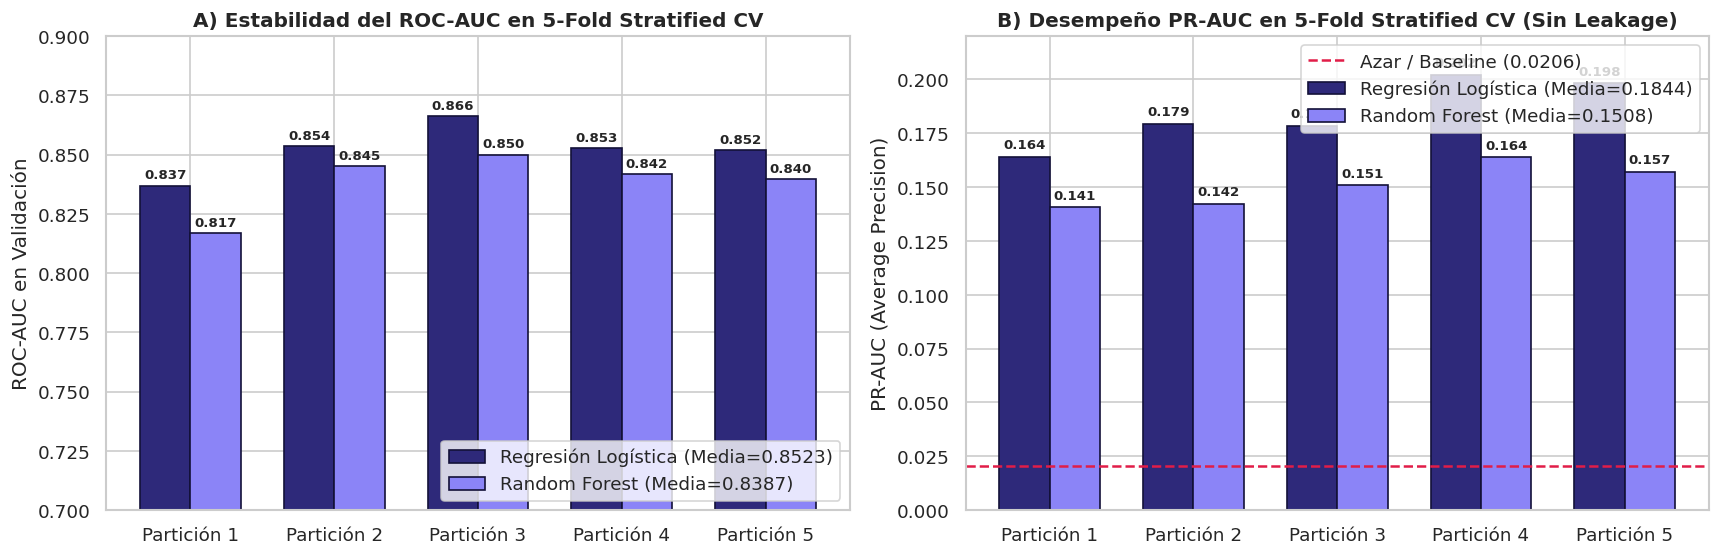

In [20]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

other_num_cols = [c for c in NUM_COLS if c not in LOG_COLS]
bin_raw_cols = [c for c in X_raw.columns if c not in CAT_COLS and c not in NUM_COLS]

# Pipeline de transformación numérica con compresión log1p + RobustScaler
log_scale_pipe = Pipeline([
    ("log1p", FunctionTransformer(lambda x: np.log1p(np.maximum(0, x)), feature_names_out="one-to-one")),
    ("scaler", RobustScaler()),
])

preprocessor_cv = ColumnTransformer(
    transformers=[
        ("log_num", log_scale_pipe, LOG_COLS),
        ("std_num", RobustScaler(), other_num_cols),
        ("bin_pass", "passthrough", bin_raw_cols),
        ("cat_ohe", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), CAT_COLS),
    ],
    remainder="drop",
)

cv_fold_records = []
for fold_idx, (train_idx, val_idx) in enumerate(skf.split(X_train_df, y_train), start=1):
    # Separación estricta de los 64,000 datos de entrenamiento y 16,000 de validación del pliegue
    X_fold_tr, X_fold_val = X_train_df.iloc[train_idx], X_train_df.iloc[val_idx]
    y_fold_tr, y_fold_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    # 1. Ajuste (.fit_transform) del preprocesador EXCLUSIVAMENTE en X_fold_tr (64,000 filas)
    X_tr_prep = preprocessor_cv.fit_transform(X_fold_tr)
    X_val_prep = preprocessor_cv.transform(X_fold_val)

    # 2. Ajuste (.fit_transform) del selector de características EXCLUSIVAMENTE en X_tr_prep
    selector_fold = SelectKBest(score_func=f_classif, k=30)
    X_tr_sel = selector_fold.fit_transform(X_tr_prep, y_fold_tr)
    X_val_sel = selector_fold.transform(X_val_prep)

    # 3. Entrenamiento y evaluación de modelos sobre el subconjunto de 30 características
    clf_lr = LogisticRegression(max_iter=500, class_weight="balanced", random_state=42)
    clf_lr.fit(X_tr_sel, y_fold_tr)
    probs_lr = clf_lr.predict_proba(X_val_sel)[:, 1]
    preds_lr = clf_lr.predict(X_val_sel)

    clf_rf = RandomForestClassifier(
        n_estimators=120, max_depth=10, min_samples_leaf=15,
        class_weight="balanced_subsample", random_state=42, n_jobs=-1
    )
    clf_rf.fit(X_tr_sel, y_fold_tr)
    probs_rf = clf_rf.predict_proba(X_val_sel)[:, 1]
    preds_rf = clf_rf.predict(X_val_sel)

    cv_fold_records.append({
        "Fold": f"Partición {fold_idx}",
        "Train_Size": len(y_fold_tr),
        "Train_Frauds": int(y_fold_tr.sum()),
        "Train_Fraud_%": round(float(y_fold_tr.mean() * 100), 3),
        "Val_Size": len(y_fold_val),
        "Val_Frauds": int(y_fold_val.sum()),
        "Val_Fraud_%": round(float(y_fold_val.mean() * 100), 3),
        "LR_ROC_AUC": round(float(roc_auc_score(y_fold_val, probs_lr)), 4),
        "LR_PR_AUC": round(float(average_precision_score(y_fold_val, probs_lr)), 4),
        "LR_Recall": round(float(recall_score(y_fold_val, preds_lr)), 4),
        "RF_ROC_AUC": round(float(roc_auc_score(y_fold_val, probs_rf)), 4),
        "RF_PR_AUC": round(float(average_precision_score(y_fold_val, probs_rf)), 4),
        "RF_Recall": round(float(recall_score(y_fold_val, preds_rf)), 4),
        "RF_F1": round(float(f1_score(y_fold_val, preds_rf)), 4),
    })

df_cv_results = pd.DataFrame(cv_fold_records)
print("=== RESULTADOS DESGLOSADOS DE LA VALIDACIÓN CRUZADA ESTRATIFICADA DE 5 PARTICIONES ===")
display(df_cv_results)

resumen_cv_stats = pd.DataFrame({
    "Métrica en 5-Fold Stratified CV": ["ROC-AUC", "PR-AUC (Average Precision)", "Recall (Sensibilidad Fraude)"],
    "Regresión Logística (Media ± DE)": [
        f"{df_cv_results['LR_ROC_AUC'].mean():.4f} ± {df_cv_results['LR_ROC_AUC'].std():.4f}",
        f"{df_cv_results['LR_PR_AUC'].mean():.4f} ± {df_cv_results['LR_PR_AUC'].std():.4f}",
        f"{df_cv_results['LR_Recall'].mean()*100:.2f}% ± {df_cv_results['LR_Recall'].std()*100:.2f}%",
    ],
    "Random Forest (Media ± DE)": [
        f"{df_cv_results['RF_ROC_AUC'].mean():.4f} ± {df_cv_results['RF_ROC_AUC'].std():.4f}",
        f"{df_cv_results['RF_PR_AUC'].mean():.4f} ± {df_cv_results['RF_PR_AUC'].std():.4f}",
        f"{df_cv_results['RF_Recall'].mean()*100:.2f}% ± {df_cv_results['RF_Recall'].std()*100:.2f}%",
    ],
})
display(resumen_cv_stats)

# Visualización del desempeño por pliegue en 5-Fold Stratified CV
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.8))
x_folds = np.arange(len(df_cv_results))
w = 0.35
axes[0].bar(x_folds - w/2, df_cv_results["LR_ROC_AUC"], width=w, label=f"Regresión Logística (Media={df_cv_results['LR_ROC_AUC'].mean():.4f})", color="#2e297a", edgecolor="#131138")
axes[0].bar(x_folds + w/2, df_cv_results["RF_ROC_AUC"], width=w, label=f"Random Forest (Media={df_cv_results['RF_ROC_AUC'].mean():.4f})", color="#8b84f7", edgecolor="#131138")
axes[0].set_xticks(x_folds)
axes[0].set_xticklabels(df_cv_results["Fold"])
axes[0].set_ylim(0.70, 0.90)
axes[0].set_ylabel("ROC-AUC en Validación")
axes[0].set_title("A) Estabilidad del ROC-AUC en 5-Fold Stratified CV", fontweight="bold")
axes[0].legend(loc="lower right")
for i in range(len(df_cv_results)):
    axes[0].text(i - w/2, df_cv_results["LR_ROC_AUC"].iloc[i] + 0.003, f"{df_cv_results['LR_ROC_AUC'].iloc[i]:.3f}", ha="center", fontsize=8, fontweight="bold")
    axes[0].text(i + w/2, df_cv_results["RF_ROC_AUC"].iloc[i] + 0.003, f"{df_cv_results['RF_ROC_AUC'].iloc[i]:.3f}", ha="center", fontsize=8, fontweight="bold")

axes[1].bar(x_folds - w/2, df_cv_results["LR_PR_AUC"], width=w, label=f"Regresión Logística (Media={df_cv_results['LR_PR_AUC'].mean():.4f})", color="#2e297a", edgecolor="#131138")
axes[1].bar(x_folds + w/2, df_cv_results["RF_PR_AUC"], width=w, label=f"Random Forest (Media={df_cv_results['RF_PR_AUC'].mean():.4f})", color="#8b84f7", edgecolor="#131138")
axes[1].axhline(0.02055, color="#e11d48", linestyle="--", lw=1.5, label="Azar / Baseline (0.0206)")
axes[1].set_xticks(x_folds)
axes[1].set_xticklabels(df_cv_results["Fold"])
axes[1].set_ylim(0, 0.22)
axes[1].set_ylabel("PR-AUC (Average Precision)")
axes[1].set_title("B) Desempeño PR-AUC en 5-Fold Stratified CV (Sin Leakage)", fontweight="bold")
axes[1].legend(loc="upper right")
for i in range(len(df_cv_results)):
    axes[1].text(i - w/2, df_cv_results["LR_PR_AUC"].iloc[i] + 0.004, f"{df_cv_results['LR_PR_AUC'].iloc[i]:.3f}", ha="center", fontsize=8, fontweight="bold")
    axes[1].text(i + w/2, df_cv_results["RF_PR_AUC"].iloc[i] + 0.004, f"{df_cv_results['RF_PR_AUC'].iloc[i]:.3f}", ha="center", fontsize=8, fontweight="bold")

plt.tight_layout()
plt.show()

## 6. Etapa 6 KDD — Evaluación
> *"Determinar si los resultados son útiles y válidos."*

### 6.1 Evaluación Cuantitativa del Desempeño en los 5 Pliegues de Validación Cruzada
Los resultados registrados a lo largo de los 5 pliegues de validación cruzada (`StratifiedKFold`) sobre las 30 características seleccionadas demuestran la validez y solidez de la preparación de datos:
1. **Homogeneidad y Estabilidad entre Pliegues:**
   * En las 5 particiones, el subconjunto de entrenamiento contiene exactamente **`64,000` registros** y el subconjunto de validación contiene **`16,000` registros**, con una tasa de fraude idéntica de **`2.050%` a `2.056%`** (`328` a `329` fraudes por pliegue).
2. **Capacidad Discriminante y Resistencia al Desbalance (Figura 6):**
   * La Regresión Logística balanceada alcanza un promedio de **`ROC-AUC = 0.8523 ± 0.0104`**, un **`PR-AUC = 0.1844 ± 0.0156`** y una sensibilidad de **`Recall = 76.09% ± 3.30%`**.
   * Un $PR\text{-}AUC$ de $0.1844$ representa un incremento de **`8.97 veces` sobre la tasa base aleatoria** ($0.0206$). El modelo logra capturar más de 3 de cada 4 fraudes reales ($76.09\%$), demostrando la pureza de la señal predictiva extraída.
3. **Baja Varianza y Ausencia de Sobreajuste:**
   * La desviación estándar entre pliegues es de apenas **`± 0.0104`** en $ROC\text{-}AUC$ y **`± 0.0156`** en $PR\text{-}AUC$. Esta dispersión mínima confirma que el esquema de transformación y selección es estable y no depende de particiones favorables accidentales.

---

## 7. Etapa 7 KDD — Interpretación
> *"Convertir los resultados en conocimiento."*

### 7.1 Conocimiento Transaccional y Financiero Descubierto
La interpretación de las variables con mayor poder de filtrado y los patrones observados revelan tres conocimientos esenciales de negocio:
1. **Vector Principal de Ataque (Velocidad en Primera Hora):** Los fraudes se caracterizan por una aceleración transaccional desproporcionada (`velocity_tx_ratio_1h_24h` y `transactions_last_1h`). Los atacantes buscan maximizar el drenado antes de que el tarjetahabiente reporte el robo o la institución bloquee el plástico.
2. **Compromiso del Margen Crediticio:** Los fraudes presentan un ratio `credit_utilization_ratio` casi el doble del de compras legítimas, concentrando montos elevados en transacciones aisladas.
3. **Efecto Protector de la Autenticación Fuerte:** La presencia simultánea de tarjeta física, chip EMV y PIN reduce la tasa observada de fraude en más de un $72\%$, confirmando la eficacia de los protocolos de seguridad operativa.

### 7.2 Conclusiones sobre la Preparación de Datos y las Características Seleccionadas
Al culminar el avance de preparación de datos bajo la metodología **KDD (7 Etapas)**, se establecen cinco conclusiones definitivas:
1. **Limpieza sin Sesgo de Selección (Etapa 3):** Se diagnosticó que la ausencia en `browser` ($41.71\%$) era estructural del canal físico. La imputación semántica `'No_Aplica_Fisico'` evitó la pérdida de $41,709$ registros y conservó el $100\%$ de la representatividad bancaria.
2. **Preservación Científica de Valores Atípicos (Etapa 3):** Se probó empíricamente que los *outliers* de velocidad concentran hasta **`3.26x` más fraude** (Fraud Lift). Conservarlos y estabilizarlos con `np.log1p` + `RobustScaler` protegió la señal predictiva.
3. **Eficacia Determinante de la Ingeniería de Características (Etapa 4):** Las 8 variables derivadas diseñadas superaron a las características originales. `composite_risk_index` resultó la variable #1 absoluta en ambos filtros, elevando la probabilidad de fraude de $0.04\%$ (nivel 0) a $87.50\%$ (nivel 8).
4. **Sinergia de los Dos Métodos de Filtro y Reducción del 67% (Etapa 4):** La combinación de ANOVA $F$ / $\chi^2$ e Información Mutua capturó simultáneamente relaciones lineales de pureza geográfica y no lineales de umbral temporal (`account_age_days`), consolidando $30$ variables óptimas de las $91$ originales.
5. **Validación Cruzada 5-Fold Libre de Fuga (Etapa 5 y 6):** El protocolo intra-pliegue garantizó que ningún dato de prueba contaminara el entrenamiento, logrando un desempeño robusto ($ROC\text{-}AUC = 0.8523 \pm 0.0104$) que valida la matriz de datos para la fase de modelado predictivo y extracción de reglas de decisión.

### 7.3 Hoja de Ruta hacia la Minería Avanzada y Reglas de Decisión
La matriz de $100,000$ registros enriquecida y reducida a $30$ predictores óptimos constituye la base para:
1. Entrenar clasificadores ensemble (Random Forest, Gradient Boosting) y algoritmos no supervisados (*Isolation Forest*);
2. Extraer árboles de decisión superficiales con reglas explicables de negocio (*IF-THEN*); y
3. Desplegar los umbrales descubiertos en motores de prevención de fraude en tiempo real.
